# TV6 — tích hợp, đánh giá cuối và demo

        **Trạng thái hiện tại: mục1–9 đã hoàn thành local theo phạm vi từng mục, gồm release/inference, API và frontend AAPL Forecast Lab. Residual được đánh giá sau phát triển trên test đã quan sát, không phải test độc lập mới. Mục10 còn chờ. Các nhận xét chưa mở test/chưa có API/frontend ở các mục trước phản ánh giai đoạn lịch sử tương ứng.**

        ## 1. Nghiệm thu đầu vào TV1–TV5

        Đối chiếu snapshot/hash TV1, scaler/prepared TV2, model contract TV3 và best validation checkpoints TV4/TV5. Danh mục gồm ba LSTM một bước lookback30, ba LSTM năm bước và ba CNN một bước theo seed42/123/456. Không lấy checkpoint mới nhất trên đĩa hoặc chọn seed theo test.

        CLI `python scripts/audit_tv6_inputs.py` chạy lại kiểm dữ liệu/provenance/history/hash và forward hai input validation cho mỗi model. Chỉ kiểm schema/coverage test, không dự đoán hoặc tính metric test. Mục2 sẽ khóa protocol đánh giá cuối; chưa chọn release/demo seed hoặc làm frontend.

**Bổ sung sau test:** cuối notebook có chẩn đoán persistence gap và thử nghiệm cải tiến residual trên validation2022/2023; giữ nguyên kết quả test chính thức. Đây là development, không phải test độc lập mới.

In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
pointer=json.loads((ROOT/'logs/audit/tv6_item1_latest.json').read_text(encoding='utf-8'))
inventory=json.loads((ROOT/pointer['evidence']).read_text(encoding='utf-8'))
assert inventory['passed'] and len(inventory['models'])==9
assert not inventory['test_performance_evaluated'] and not inventory['trained_again']
assert not inventory['release_selected']
for name,expected in inventory['files'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==expected,name
display(pd.DataFrame([{'dataset_version':inventory['dataset_version'],'snapshot_rows':inventory['snapshot_rows'],
    'models':len(inventory['models']),'artifact_files':len(inventory['files']),
    'test_evaluated':inventory['test_performance_evaluated']}]))
display(pd.DataFrame(inventory['models']))
display(pd.DataFrame(inventory['coverage']))
display(pd.DataFrame([{'item':i,'status':'Đạt nghiệm thu local' if i==1 else 'Chờ theo flow'} for i in range(1,11)]))
print('Bằng chứng',ROOT/pointer['evidence'])
print('Còn mở',inventory['pending'])
display(Markdown('**Mục1 nghiệm thu artifacts local. Tiếp theo mục2, khóa protocol đánh giá cuối trước test.**'))

,dataset_version,snapshot_rows,models,artifact_files,test_evaluated
0,aapl_2015_2025_acq_20261119T141302002415Z,2766,9,120,False


,method,forecast_length,lookback,seed,run_id,best_epoch,checkpoint,prepared_id,scaler_id,history_verified,probe_split,parameters
0,LSTM,1,30,42,lstm_one_step__lstm_one_step_lb30_common60__se...,97,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4513
1,LSTM,1,30,123,lstm_one_step__lstm_one_step_lb30_common60__se...,97,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4513
2,LSTM,1,30,456,lstm_one_step__lstm_one_step_lb30_common60__se...,75,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4513
3,LSTM,5,30,42,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4645
4,LSTM,5,30,123,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4645
5,LSTM,5,30,456,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,4645
6,CNN,1,30,42,cnn_one_step__cnn_one_step_option_a__seed42__2...,32,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,17057
7,CNN,1,30,123,cnn_one_step__cnn_one_step_option_a__seed123__...,41,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,17057
8,CNN,1,30,456,cnn_one_step__cnn_one_step_option_a__seed456__...,43,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z,True,validation_inputs_only,17057


,forecast_length,split,samples,input_shape,target_shape,first_target,last_target,ordered_ids_sha256
0,1,train,1954,"[1954, 30, 1]","[1954, 1]",2015-03-31,2022-12-30,f54f5c66f2c00e01a73c3d75ae2c4a534c5a4c41e99178...
1,1,val,250,"[250, 30, 1]","[250, 1]",2023-01-03,2023-12-29,f396ebb9da19ba432de552b77c76daf6f15487f953a92c...
2,1,test_schema_only,502,"[502, 30, 1]","[502, 1]",NaN,NaN,NaN
3,5,train,1980,"[1980, 30, 1]","[1980, 5]",2015-02-17,2022-12-30,dc4bb8cb1d602e63c387707a8ae3ff0e4d15353e166cf2...
4,5,val,246,"[246, 30, 1]","[246, 5]",2023-01-03,2023-12-29,b147c99b6ae99855c888011d49df1727a3c5a67cd8c08f...
5,5,test_schema_only,498,"[498, 30, 1]","[498, 5]",NaN,NaN,NaN


,item,status
0,1,Đạt nghiệm thu local
1,2,Chờ theo flow
2,3,Chờ theo flow
3,4,Chờ theo flow
4,5,Chờ theo flow
5,6,Chờ theo flow
6,7,Chờ theo flow
7,8,Chờ theo flow
8,9,Chờ theo flow
9,10,Chờ theo flow


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item1_20261126T160646012874Z\inventory.json
Còn mở ['item2 final evaluation protocol and demo model selection rule', 'items3-10 inference/evaluation/test/release/API/frontend/final handoff', 'recipient machine verification and historical peak RAM']


**Mục1 nghiệm thu artifacts local. Tiếp theo mục2, khóa protocol đánh giá cuối trước test.**

### Kiểm lại bộ dữ liệu bàn giao

        Chạy lại acceptance/calendar/schema/hash TV1, recompute thống kê scaler từ train, audit toàn bộ eligible windows của cả hai mode trong từng prepared bundle. Kiểm float64/finite, inverse X/y khớp raw JSON, thứ tự/ngày/độ phủ/ràng buộc mọi target cùng split. Đối chiếu bytes của dữ liệu local với ZIP đã bàn giao, cùng provenance9 checkpoint.

        raw_window_samples là số windows trong prepared gốc; một bước consumer common-history60 còn lọc các target chưa đủ60 phiên, không đổi input30. Năm bước giữ config TV4 không lọc common-history60. Kiểm test ở đây chỉ kiểm dữ liệu/schema/coverage, không tính prediction/metric hoặc tuning. CLI `python scripts/recheck_tv6_data.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
data_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
data_pointer=json.loads((data_root/'logs/audit/tv6_data_recheck_latest.json').read_text(encoding='utf-8'))
data_receipt=json.loads((data_root/data_pointer['evidence']).read_text(encoding='utf-8'))
assert data_receipt['passed'] and not data_receipt['test_performance_evaluated']
display(pd.DataFrame([{k:data_receipt[k] for k in ['snapshot_rows','first_date','last_date',
    'inventory_hashes_verified','zip_data_files_verified','models_provenance_verified',
    'inverse_matches_raw','temporal_coverage_verified','files_unchanged']}]))
display(pd.DataFrame([data_receipt['scaler_train_statistics']]))
display(pd.DataFrame(data_receipt['coverage']))
print('Ví dụ ranh giới', (data_root/data_pointer['evidence']).parent/'boundary_examples.json')
print('Bằng chứng',data_root/data_pointer['evidence'])

,snapshot_rows,first_date,last_date,inventory_hashes_verified,zip_data_files_verified,models_provenance_verified,inverse_matches_raw,temporal_coverage_verified,files_unchanged
0,2766,2015-01-02,2025-12-31,120,45,9,True,True,True


,passed,fit_rows,mean,variance_ddof0,scale
0,True,2014,70.088454,2360.73829,48.587429


,prepared_id,forecast_length,split,raw_window_samples,samples_if_common_history60,first_origin,first_target,last_target,dtype,cross_split_excluded,incomplete_excluded
0,tv2_prepared_20261122T145943242978Z,1,train,1984,1954,2015-02-13,2015-02-17,2022-12-30,float64,0,0
1,tv2_prepared_20261122T145943242978Z,1,val,250,250,2022-12-30,2023-01-03,2023-12-29,float64,0,0
2,tv2_prepared_20261122T145943242978Z,1,test,502,502,2023-12-29,2024-01-02,2025-12-31,float64,0,0
3,tv2_prepared_20261122T145943242978Z,5,train,1980,1950,2015-02-13,2015-02-17,2022-12-30,float64,4,0
4,tv2_prepared_20261122T145943242978Z,5,val,246,246,2022-12-30,2023-01-03,2023-12-29,float64,4,0
5,tv2_prepared_20261122T145943242978Z,5,test,498,498,2023-12-29,2024-01-02,2025-12-31,float64,0,4
6,tv4_lb30_20261125T120957429763Z,1,train,1984,1954,2015-02-13,2015-02-17,2022-12-30,float64,0,0
7,tv4_lb30_20261125T120957429763Z,1,val,250,250,2022-12-30,2023-01-03,2023-12-29,float64,0,0
8,tv4_lb30_20261125T120957429763Z,1,test,502,502,2023-12-29,2024-01-02,2025-12-31,float64,0,0
9,tv4_lb30_20261125T120957429763Z,5,train,1980,1950,2015-02-13,2015-02-17,2022-12-30,float64,4,0


Ví dụ ranh giới D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_data_recheck_20261126T162229495967Z\boundary_examples.json
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_data_recheck_20261126T162229495967Z\summary.json


## 2. Khóa protocol đánh giá cuối trước test

        Inventory đã nghiệm thu → protocol v1 + fingerprint → inference/evaluation ở các mục sau. Giữ9 model,3 seed mỗi nhóm; một bước502 samples, năm bước498. Khóa ordered sample/origin/target-date keys và artifacts SHA256, không âm thầm bỏ/trộn mẫu. Rolling input là lịch sử đã quan sát, weights/scaler giữ nguyên.

        Báo MAE/RMSE USD từng seed và mean/std mẫu ddof1, từng horizon1–5; overall h5 là flatten errors, không lấy trung bình RMSE của5 horizon. Baseline deterministic báo một lần. Demo seed42 cố định cho từng neural group, không chọn theo test hoặc tạo ensemble. Numeric tie1e-12USD không phải ngưỡng ý nghĩa thực tiễn/thống kê.

        CLI `python scripts/lock_tv6_protocol.py` chỉ tạo một lần hoặc kiểm lại lock; có drift thì từ chối thay vì ghi đè. Chưa chạy model trên test, chưa triển khai mục3/inference hoặc frontend. Xem docs/TV6_Final_Evaluation_Protocol.md.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Markdown
protocol_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
if str(protocol_root) not in sys.path: sys.path.insert(0,str(protocol_root))
from backend.audit.tv6_protocol import validate_protocol
protocol_path=protocol_root/'experiments/configs/tv6_evaluation_protocol_v1.json'
protocol=json.loads(protocol_path.read_text(encoding='utf-8'))
protocol_sha=validate_protocol(protocol,protocol_root)
assert protocol['test_performance_evaluated_at_lock'] is False
semantic=protocol['semantic']
display(pd.DataFrame(semantic['models']))
display(pd.DataFrame(semantic['cohorts']))
display(pd.DataFrame([semantic['demo']]))
display(semantic['metrics'])
display(semantic['evaluation_policy'])
display(pd.DataFrame([{'item':i,'status':'Đạt local' if i<=2 else 'Chờ theo flow'} for i in range(1,11)]))
print('Protocol fingerprint',protocol_sha)
print('Lock',protocol_path)
print('Tests chống drift',protocol_root/'logs/audit/tv6_item2_tests.xml')
display(Markdown('**Mục2 khóa protocol đã đạt. Tiếp theo mục3, hoàn thiện inference/persistence; chưa đánh giá test.**'))

,method,forecast_length,lookback,seed,run_id,best_epoch,checkpoint,prepared_id,scaler_id
0,LSTM,1,30,42,lstm_one_step__lstm_one_step_lb30_common60__se...,97,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z
1,LSTM,1,30,123,lstm_one_step__lstm_one_step_lb30_common60__se...,97,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z
2,LSTM,1,30,456,lstm_one_step__lstm_one_step_lb30_common60__se...,75,artifacts/checkpoints/tv4_item8_20261125T12264...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z
3,LSTM,5,30,42,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z
4,LSTM,5,30,123,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z
5,LSTM,5,30,456,lstm_multi_step__lstm_multi_step_baseline__see...,100,artifacts/checkpoints/tv4_item9_20261125T14032...,tv2_prepared_20261122T145943242978Z,aapl_scaler_20261120T124720810874Z
6,CNN,1,30,42,cnn_one_step__cnn_one_step_option_a__seed42__2...,32,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z
7,CNN,1,30,123,cnn_one_step__cnn_one_step_option_a__seed123__...,41,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z
8,CNN,1,30,456,cnn_one_step__cnn_one_step_option_a__seed456__...,43,logs/audit/tv5_item8_20261126T044554616259Z/ch...,tv4_lb30_20261125T120957429763Z,aapl_scaler_20261120T124720810874Z


,forecast_length,prepared_id,samples,ordered_keys_sha256,first_origin,first_target,last_target,methods,evaluation_style
0,1,tv4_lb30_20261125T120957429763Z,502,fb0bc154a459cce87ada06198ded9e9d1ca946520dda9a...,2023-12-29,2024-01-02,2025-12-31,"[LSTM, CNN, persistence]",rolling observed history; frozen weights/scale...
1,5,tv2_prepared_20261122T145943242978Z,498,1ab6afe92c9ac3bd8b5482da63c12c0dafe452d29bb2f9...,2023-12-29,2024-01-02,2025-12-31,"[LSTM, persistence]",rolling observed history; frozen weights/scale...


,seed,rule,run_ids,default_method_policy
0,42,"fixed seed42 for all neural methods/modes, cho...",[lstm_one_step__lstm_one_step_lb30_common60__s...,show supported methods; no automatic test winn...


{'primary': ['MAE_USD', 'RMSE_USD'],
 'currency': 'USD',
 'round_before_metric': False,
 'per_horizon': True,
 'multi_step_secondary_overall': 'flatten all sample-horizon errors; sqrt of mean squared errors',
 'seed_summary': 'mean of per-seed metrics and sample std ddof1; no ensemble',
 'std_ddof': 1,
 'pooling_seed_predictions': False,
 'compare_only_identical_ordered_keys': True,
 'float64_numeric_tie_atol_usd': 1e-12,
 'practical_significance_threshold': None,
 'significance_claim': False,
 'baseline': 'last observed raw USD input, repeat for h5'}

{'no_retraining': True,
 'no_refit_scaler': True,
 'no_test_tuning': True,
 'no_seed_selection_on_test': True,
 'checkpoint_selection': 'already accepted validation best epoch',
 'missing_or_misaligned_samples': 'fail comparison; no silent intersection/drop',
 'changed_artifact': 'invalidate protocol and require explicit version change',
 'tie_interpretation': 'numeric equality only, not practical or statistical equivalence',
 'mixed_mae_rmse': 'report tradeoff, no composite score',
 'rolling_error_window_sessions': 20,
 'largest_errors_per_run': 10,
 'scope': 'full frozen test primary; subsets clearly labelled exploratory'}

,item,status
0,1,Đạt local
1,2,Đạt local
2,3,Chờ theo flow
3,4,Chờ theo flow
4,5,Chờ theo flow
5,6,Chờ theo flow
6,7,Chờ theo flow
7,8,Chờ theo flow
8,9,Chờ theo flow
9,10,Chờ theo flow


Protocol fingerprint 9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98ddb8349a4906119579
Lock D:\learn_DeepLearning\Project_course-work\experiments\configs\tv6_evaluation_protocol_v1.json
Tests chống drift D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item2_tests.xml


**Mục2 khóa protocol đã đạt. Tiếp theo mục3, hoàn thiện inference/persistence; chưa đánh giá test.**

### Audit và siết các điểm khóa protocol v1

        Thay assert bằng explicit guards, kiểm kiểu format/schema, path không thoát root và mọi model/data reference phải nằm trong intake hash. Đối chiếu model/run/seed/epoch/provenance với manifest thật, kiểm toàn bộ eligible cohort/history/date order từ snapshot. Registry riêng ghim bytes/fingerprint của lock cũ và receipt trước đó, không tự tái tạo khi mất lock hoặc mất cả lock/registry nhưng còn dấu vết lịch sử.

        Giữ nguyên bytes protocol v1,9 checkpoint,502/498 samples,metric và demo seed42. Không inference/test performance. Registry là bằng chứng consistency local, không phải chữ ký hoặc bằng chứng không ai đã chạy test bằng công cụ khác. Các guard phải được dùng trong các mục inference/evaluation tiếp theo.

In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
from IPython.display import display
audit_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
audit_pointer=json.loads((audit_root/'logs/audit/tv6_protocol_audit_latest.json').read_text(encoding='utf-8'))
audit_lock=json.loads((audit_root/audit_pointer['evidence']).read_text(encoding='utf-8'))
assert audit_lock['passed'] and audit_lock['tests']==45
assert audit_lock['original_protocol_bytes_unchanged'] and not audit_lock['test_performance_evaluated']
for name,expected in audit_lock['source_hashes'].items():
    assert hashlib.sha256((audit_root/name).read_bytes()).hexdigest()==expected,name
display(pd.DataFrame([{k:audit_lock[k] for k in ['passed','tests','protocol_tests','models','cohorts',
    'original_protocol_bytes_unchanged','registry_unchanged_on_verify','test_performance_evaluated']}]))
display(pd.DataFrame([{'fix':v,'status':'Đã kiểm chứng'} for v in audit_lock['fixes']]))
print('Fingerprint giữ nguyên',audit_lock['semantic_sha256'])
print('Giới hạn',audit_lock['limitations'])
print('Bằng chứng',audit_root/audit_pointer['evidence'])

,passed,tests,protocol_tests,models,cohorts,original_protocol_bytes_unchanged,registry_unchanged_on_verify,test_performance_evaluated
0,True,45,28,9,"[502, 498]",True,True,False


,fix,status
0,explicit guards survive Python -O and strict f...,Đã kiểm chứng
1,root-contained pinned paths,Đã kiểm chứng
2,unique model/run references tied to actual man...,Đã kiểm chứng
3,cohort completeness/history/identity from sour...,Đã kiểm chứng
4,separate registry with prior receipt and no si...,Đã kiểm chứng


Fingerprint giữ nguyên 9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98ddb8349a4906119579
Giới hạn ['Local checksums/registry are not digital signatures or proof of absence of external test exposure', 'Final evaluation/inference enforcement still requires upcoming TV6 steps3-5']
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_protocol_audit_20261126T164022898092Z\summary.json


## 3. Inference và persistence một/năm bước

        Forecast Input → protocol/registry guard → kiểm lịch sử snapshot → adapter CPU float64 → model eval/inference_mode hoặc persistence → inverse USD → prediction records. Không nhận target/y/actual hoặc checkpoint/scaler path từ request, không fit/update weights. Một bước LSTM/CNN/persistence; năm bước LSTM direct/persistence. Seed42 demo mặc định, research giữ3 seed.

        Mục3 chỉ cho phép target dates validation2023. Yêu cầu chạm test2024–2025 bị chặn trước forward; bước5 final evaluator mới tích hợp đường test sau bước4. Target dates lấy theo thứ tự phiên snapshot, không cộng ngày lịch. Không phát hành release/API/frontend, release_id hiện null có chủ đích.

        CLI `python scripts/check_tv6_inference.py` đối chiếu toàn bộ validation với inference trực tiếp trên X đã lưu; không tính metric hoặc ghép actual. Bảng/biểu đồ dưới chỉ hiển thị prediction USD, không dùng để kết luận chất lượng.

,method,forecast_length,seed,input_samples,output_rows,tail_samples,max_abs_direct_difference,dates_match_prepared,finite_usd
0,lstm,1,42.0,250,250,26,0.0,True,True
1,cnn,1,42.0,250,250,26,0.0,True,True
2,persistence,1,NaN,250,250,26,0.0,True,True
3,lstm,1,123.0,250,250,26,0.0,True,True
4,cnn,1,123.0,250,250,26,0.0,True,True
5,lstm,1,456.0,250,250,26,0.0,True,True
6,cnn,1,456.0,250,250,26,0.0,True,True
7,lstm,5,42.0,246,1230,22,0.0,True,True
8,persistence,5,NaN,246,1230,22,0.0,True,True
9,lstm,5,123.0,246,1230,22,0.0,True,True


,models,output_rows,test_inference_enabled,metrics_calculated,trained_again,source_artifacts_unchanged
0,9,6670,False,False,False,True


,method,seed,forecast_origin,target_date,horizon_step,predicted_price,currency,run_id
0,lstm,42.0,2022-12-30,2023-01-03,1,127.472201,USD,lstm_one_step__lstm_one_step_lb30_common60__se...
1,cnn,42.0,2022-12-30,2023-01-03,1,132.804748,USD,cnn_one_step__cnn_one_step_option_a__seed42__2...
2,persistence,NaN,2022-12-30,2023-01-03,1,127.554581,USD,NaN


,method,seed,forecast_origin,target_date,horizon_step,predicted_price,currency,run_id
1750,lstm,42.0,2022-12-30,2023-01-03,1,131.502464,USD,lstm_multi_step__lstm_multi_step_baseline__see...
1751,lstm,42.0,2022-12-30,2023-01-04,2,131.494473,USD,lstm_multi_step__lstm_multi_step_baseline__see...
1752,lstm,42.0,2022-12-30,2023-01-05,3,132.074326,USD,lstm_multi_step__lstm_multi_step_baseline__see...
1753,lstm,42.0,2022-12-30,2023-01-06,4,131.667921,USD,lstm_multi_step__lstm_multi_step_baseline__see...
1754,lstm,42.0,2022-12-30,2023-01-09,5,131.930644,USD,lstm_multi_step__lstm_multi_step_baseline__see...
1755,persistence,NaN,2022-12-30,2023-01-03,1,127.554581,USD,NaN
1756,persistence,NaN,2022-12-30,2023-01-04,2,127.554581,USD,NaN
1757,persistence,NaN,2022-12-30,2023-01-05,3,127.554581,USD,NaN
1758,persistence,NaN,2022-12-30,2023-01-06,4,127.554581,USD,NaN
1759,persistence,NaN,2022-12-30,2023-01-09,5,127.554581,USD,NaN


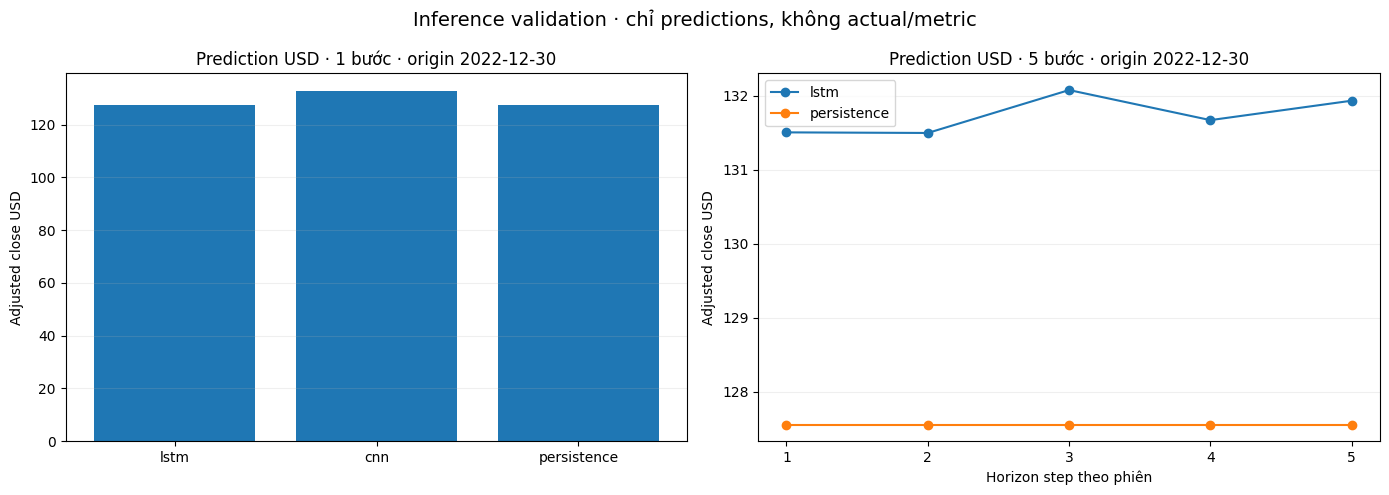

,item,status
0,1,Đạt local
1,2,Đạt local
2,3,Đạt local
3,4,Chờ theo flow
4,5,Chờ theo flow
5,6,Chờ theo flow
6,7,Chờ theo flow
7,8,Chờ theo flow
8,9,Chờ theo flow
9,10,Chờ theo flow


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item3_20261126T164900357232Z\summary.json
Giới hạn ['Historical frozen validation scope only; no live quote or future calendar beyond snapshot', 'release_id remains null until release integration; no API/frontend implementation']


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
inference_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
inference_pointer=json.loads((inference_root/'logs/audit/tv6_item3_latest.json').read_text(encoding='utf-8'))
inference_path=inference_root/inference_pointer['evidence']
inference=json.loads(inference_path.read_text(encoding='utf-8'))
assert inference['passed'] and inference['models']==9 and inference['output_rows']==6670
assert not inference['test_inference_enabled'] and not inference['metrics_calculated']
checks3=pd.read_csv(inference_path.parent/'checks.csv')
predictions3=pd.read_csv(inference_path.parent/'validation_inference_usd.csv')
display(checks3)
display(pd.DataFrame([{k:inference[k] for k in ['models','output_rows','test_inference_enabled',
    'metrics_calculated','trained_again','source_artifacts_unchanged']}]))
demo3=predictions3[(predictions3.seed==42)|predictions3.seed.isna()]
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,h in zip(axes,[1,5]):
    mode=demo3[demo3.forecast_length==h]
    example=mode[mode.sample_id==mode.sample_id.iloc[0]]
    display(example[['method','seed','forecast_origin','target_date','horizon_step','predicted_price','currency','run_id']])
    if h==1:
        ax.bar(example.method,example.predicted_price)
    else:
        for method,group in example.groupby('method'):
            ax.plot(group.horizon_step,group.predicted_price,'o-',label=method)
        ax.set_xticks(range(1,6));ax.set_xlabel('Horizon step theo phiên');ax.legend()
    ax.set_title('Prediction USD · '+str(h)+' bước · origin '+example.forecast_origin.iloc[0])
    ax.set_ylabel('Adjusted close USD');ax.grid(axis='y',alpha=.2)
fig.suptitle('Inference validation · chỉ predictions, không actual/metric',fontsize=14)
fig.tight_layout();fig.savefig(inference_path.parent/'inference_examples.png',dpi=150)
display(fig);plt.close(fig)
display(pd.DataFrame([{'item':i,'status':'Đạt local' if i<=3 else 'Chờ theo flow'} for i in range(1,11)]))
print('Bằng chứng',inference_path)
print('Giới hạn',inference['limitations'])

## 4. Evaluation USD, alignment và từng horizon

        Prediction input-only của mục3 + actual raw từ target source → kiểm cùng protocol/run/seed/ID/origin/ngày/horizon/units → residual → MAE/RMSE USD từng horizon/overall → mean/std mẫu3 seed. Không inner-join/drop mẫu âm thầm, không ensemble hoặc nhân baseline thành3 runs.

        H5 overall flatten N×5 residuals, RMSE=sqrt(mean squared errors), không mean5 RMSE; horizon_step để trống cho overall, không tạo horizon0. sample_count vẫn là số windows, error_count overall=N×5. Một bước không lặp metric overall vì giống h1. Đây là validation2023, không phải test2024–2025. Cases test-cohort trong unit tests chỉ là fixture tổng hợp.

        CLI `python scripts/check_tv6_evaluation.py` tái tính từ predictions validation đã lưu, không train/inference mới. Kiểm h1 khớp TV5, baseline khớp rawlast. Hàm metric riêng không thay xác minh nguồn actual/protocol: caller phải cung cấp artifacts đã accept và gọi guard.

,method,seed,forecast_length,horizon_step,metric_scope,sample_count,error_count,mae_usd,rmse_usd
0,lstm,42.0,1,1.0,per_horizon,250,250,1.908008,2.410920
1,cnn,42.0,1,1.0,per_horizon,250,250,3.456691,4.573323
2,persistence,NaN,1,1.0,per_horizon,250,250,1.636779,2.120593
3,lstm,123.0,1,1.0,per_horizon,250,250,2.078204,2.567211
4,cnn,123.0,1,1.0,per_horizon,250,250,3.024384,3.947099
5,lstm,456.0,1,1.0,per_horizon,250,250,2.762050,3.275205
6,cnn,456.0,1,1.0,per_horizon,250,250,3.617029,4.531784
7,lstm,42.0,5,1.0,per_horizon,246,246,2.438727,3.011988
8,lstm,42.0,5,2.0,per_horizon,246,246,3.203513,3.836943
9,lstm,42.0,5,3.0,per_horizon,246,246,3.421587,4.117136


,method,forecast_length,horizon_step,metric_scope,sample_count,error_count,mae_usd_mean,mae_usd_std,rmse_usd_mean,rmse_usd_std,std_ddof
0,lstm,1,1.0,per_horizon,250,250,2.249421,0.452032,2.751112,0.460556,1
1,cnn,1,1.0,per_horizon,250,250,3.366034,0.306547,4.350735,0.350176,1
2,lstm,5,1.0,per_horizon,246,246,2.396117,0.127018,2.978710,0.096718,1
3,lstm,5,2.0,per_horizon,246,246,2.979359,0.271702,3.639269,0.230190,1
4,lstm,5,3.0,per_horizon,246,246,3.466836,0.056944,4.161830,0.057463,1
5,lstm,5,4.0,per_horizon,246,246,3.889911,0.208964,4.720995,0.209153,1
6,lstm,5,5.0,per_horizon,246,246,4.441149,0.109651,5.385021,0.110449,1
7,lstm,5,NaN,overall,246,1230,3.434674,0.053956,4.261446,0.040648,1


,method,seed,forecast_origin,forecast_length,horizon_step,target_date,predicted_price,actual_price,error_usd
0,lstm,42.0,2022-12-30,1,1,2023-01-03,127.472201,122.78344,4.688761
250,cnn,42.0,2022-12-30,1,1,2023-01-03,132.804748,122.78344,10.021308
500,persistence,NaN,2022-12-30,1,1,2023-01-03,127.554581,122.78344,4.771141
750,lstm,123.0,2022-12-30,1,1,2023-01-03,130.198985,122.78344,7.415546
1000,cnn,123.0,2022-12-30,1,1,2023-01-03,130.961971,122.78344,8.178531
1250,lstm,456.0,2022-12-30,1,1,2023-01-03,130.337183,122.78344,7.553743
1500,cnn,456.0,2022-12-30,1,1,2023-01-03,133.884148,122.78344,11.100709
1750,lstm,42.0,2022-12-30,5,1,2023-01-03,131.502464,122.78344,8.719024
2980,persistence,NaN,2022-12-30,5,1,2023-01-03,127.554581,122.78344,4.771141
4210,lstm,123.0,2022-12-30,5,1,2023-01-03,131.612221,122.78344,8.828781


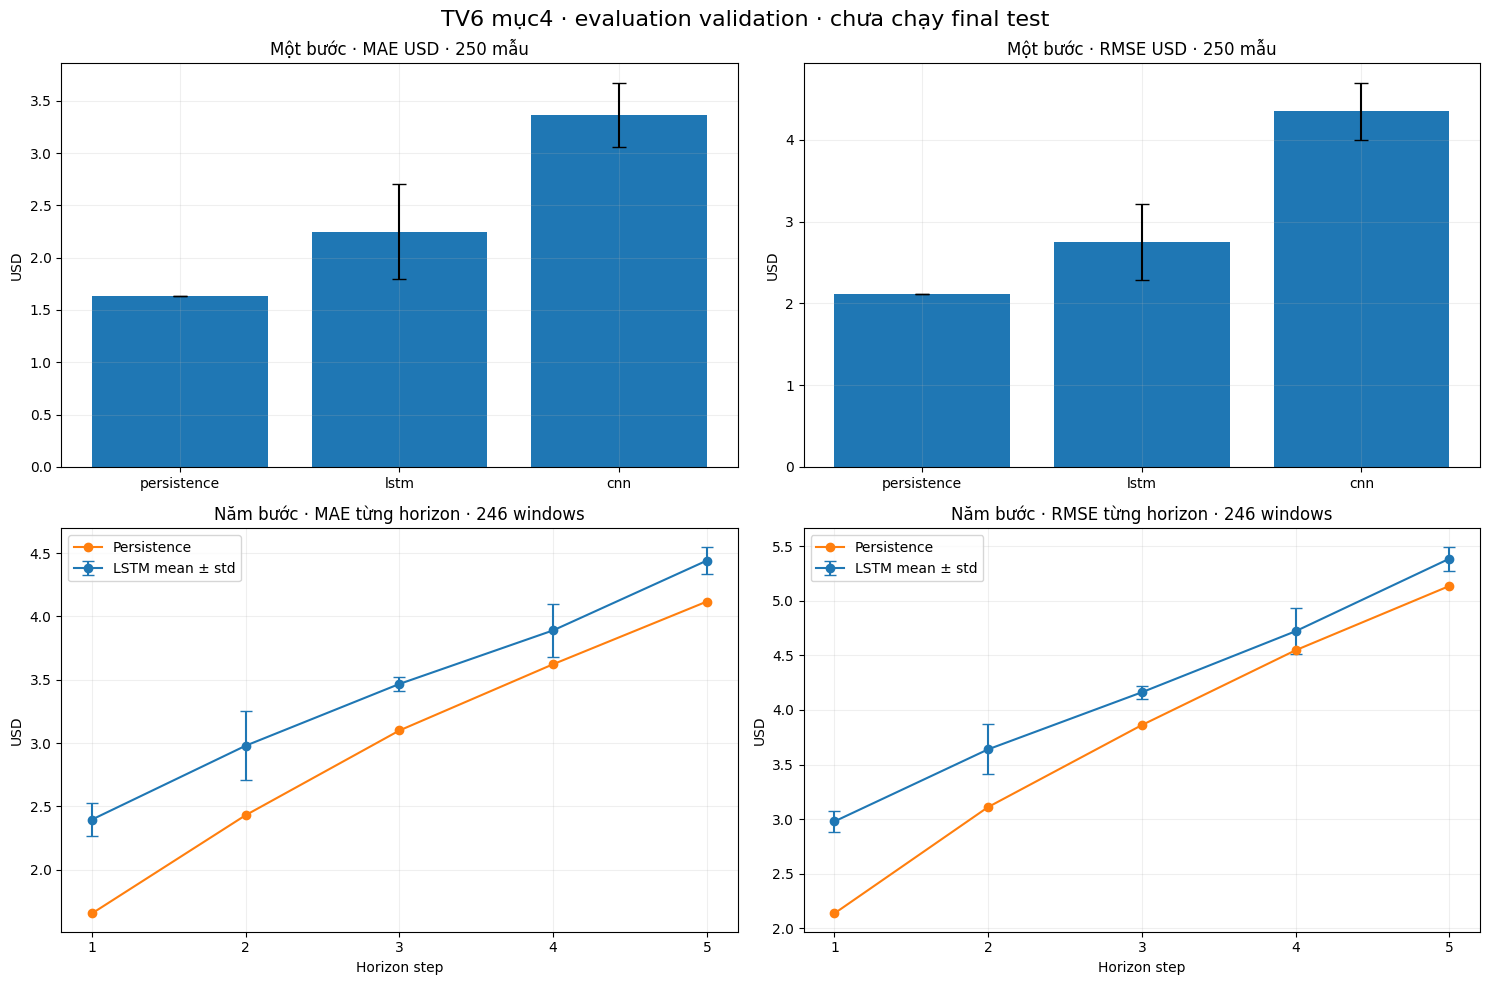

,item,status
0,1,Đạt local
1,2,Đạt local
2,3,Đạt local
3,4,Đạt local
4,5,Chờ theo flow
5,6,Chờ theo flow
6,7,Chờ theo flow
7,8,Chờ theo flow
8,9,Chờ theo flow
9,10,Chờ theo flow


Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item4_20261126T171056822137Z\summary.json
H1 khớp TV5 True
Giới hạn ['Validation used in checkpoint selection; not final held-out evidence', 'Full-test evaluator math/schema ready, but inference/test run workflow remains item5']


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
eval_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
eval_pointer=json.loads((eval_root/'logs/audit/tv6_item4_latest.json').read_text(encoding='utf-8'))
eval_path=eval_root/eval_pointer['evidence']
evaluation=json.loads(eval_path.read_text(encoding='utf-8'))
assert evaluation['passed'] and not evaluation['test_performance_evaluated']
metric4=pd.read_csv(eval_path.parent/'metrics.csv')
aggregate4=pd.read_csv(eval_path.parent/'aggregates.csv')
residual4=pd.read_csv(eval_path.parent/'residuals.csv')
display(metric4[['method','seed','forecast_length','horizon_step','metric_scope','sample_count','error_count','mae_usd','rmse_usd']])
display(aggregate4[['method','forecast_length','horizon_step','metric_scope','sample_count','error_count',
    'mae_usd_mean','mae_usd_std','rmse_usd_mean','rmse_usd_std','std_ddof']])
display(residual4.groupby(['method','forecast_length','seed'],dropna=False,sort=False).head(1)[
    ['method','seed','forecast_origin','forecast_length','horizon_step','target_date','predicted_price','actual_price','error_usd']])
fig,axes=plt.subplots(2,2,figsize=(15,10))
base1=metric4[(metric4.method=='persistence')&(metric4.forecast_length==1)].iloc[0]
one=aggregate4[aggregate4.forecast_length==1]
for ax,metric in zip(axes[0],['mae','rmse']):
    ax.bar(['persistence']+one.method.tolist(),[base1[metric+'_usd']]+one[metric+'_usd_mean'].tolist(),
        yerr=[0]+one[metric+'_usd_std'].tolist(),capsize=5)
    ax.set(title='Một bước · '+metric.upper()+' USD · 250 mẫu',ylabel='USD')
five=aggregate4[(aggregate4.forecast_length==5)&(aggregate4.metric_scope=='per_horizon')]
base5=metric4[(metric4.method=='persistence')&(metric4.forecast_length==5)&(metric4.metric_scope=='per_horizon')]
for ax,metric in zip(axes[1],['mae','rmse']):
    ax.errorbar(five.horizon_step,five[metric+'_usd_mean'],yerr=five[metric+'_usd_std'],fmt='o-',capsize=4,label='LSTM mean ± std')
    ax.plot(base5.horizon_step,base5[metric+'_usd'],'o-',label='Persistence')
    ax.set(title='Năm bước · '+metric.upper()+' từng horizon · 246 windows',xlabel='Horizon step',ylabel='USD')
    ax.set_xticks(range(1,6));ax.legend()
for ax in axes.flat:ax.grid(alpha=.2)
fig.suptitle('TV6 mục4 · evaluation validation · chưa chạy final test',fontsize=16)
fig.tight_layout();fig.savefig(eval_path.parent/'evaluation_overview.png',dpi=150)
display(fig);plt.close(fig)
display(pd.DataFrame([{'item':i,'status':'Đạt local' if i<=4 else 'Chờ theo flow'} for i in range(1,11)]))
print('Bằng chứng',eval_path)
print('H1 khớp TV5',evaluation['one_step_matches_tv5'])
print('Giới hạn',evaluation['limitations'])

### Audit lại quá trình đánh giá và dữ liệu chưa đánh giá

        Phát hiện và sửa guard full validation: nếu prediction và actual cùng bị cắt mẫu, chỉ so chúng với nhau chưa đủ. Nay caller phải cung cấp cohort đầy đủ đọc từ input/target source đã pin hash; module từ chối subset chung bị gắn nhãn toàn tập. Protocol v1/model/data không đổi, scores cũ đã xác nhận không đổi.

        Hồi quy sau sửa đạt104/104 tests, gồm3 regression mới; JUnit logs/audit/tv6_item4_audit_tests.xml.

        Audit độc lập kiểm actual theo raw snapshot, baseline theo giá origin, residual,31 metric bằng math.fsum và8 aggregate bằng statistics mean/stdev. H1 phủ đủ250 phiên2023; H5 có246 windows, loại4 target-start26–29/12/2023 vì5 target sẽ vượt split. Các horizon có ngày đầu/cuối khác nhau có chủ đích, không silently drop mẫu.

        Mục4 đủ nghiệm thu công cụ/validation, chưa hoàn thành đánh giá model cuối. Test2024–2025 vẫn để mục5; phân tích lỗi test ở mục6. Dữ liệu2026/live/intraday/OHLCV không thuộc feature/snapshot đã khóa. Overlapping h5 windows không là các quan sát độc lập để kết luận significance.

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
audit_eval_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
audit_eval_pointer=json.loads((audit_eval_root/'logs/audit/tv6_evaluation_audit_latest.json').read_text(encoding='utf-8'))
audit_eval=json.loads((audit_eval_root/audit_eval_pointer['evidence']).read_text(encoding='utf-8'))
assert audit_eval['passed'] and not audit_eval['test_performance_evaluated']
display(pd.DataFrame([{k:audit_eval[k] for k in ['metric_rows_verified','aggregate_rows_verified',
    'residual_rows_verified','raw_actual_matches_snapshot','independent_math_matches','seed_std_matches',
    'metrics_unchanged_after_guard_fix']}]))
display(pd.DataFrame(audit_eval['coverage']))
print('H5 target starts loại đúng quy tắc',audit_eval['excluded_h5_validation_target_starts'])
print('Còn chưa đánh giá',audit_eval['remaining'])
print('Bằng chứng',audit_eval_root/audit_eval_pointer['evidence'])

,metric_rows_verified,aggregate_rows_verified,residual_rows_verified,raw_actual_matches_snapshot,independent_math_matches,seed_std_matches,metrics_unchanged_after_guard_fix
0,31,8,6670,True,True,True,True


,forecast_length,horizon_step,samples,first_target,last_target
0,1,1,250,2023-01-03,2023-12-29
1,5,1,246,2023-01-03,2023-12-22
2,5,2,246,2023-01-04,2023-12-26
3,5,3,246,2023-01-05,2023-12-27
4,5,4,246,2023-01-06,2023-12-28
5,5,5,246,2023-01-09,2023-12-29


H5 target starts loại đúng quy tắc ['2023-12-26', '2023-12-27', '2023-12-28', '2023-12-29']
Còn chưa đánh giá ['held-out test2024-2025 remains item5', 'test error analysis remains item6', 'adjusted-close point-in-time and unequal tuning-budget limits remain', 'data2026/live/intraday/OHLCV are outside the frozen one-feature coursework scope']
Bằng chứng D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_evaluation_audit_20261126T171231516396Z\summary.json


## 5. Đánh giá chính thức test 2024–2025

        Input: 9 checkpoint và scaler đã khóa, ba seed42/123/456, 502 mẫu h1 và498 cửa sổ h5. Không train lại, không chọn seed theo test. Nhật ký execution.json được ghi trước test forward; inference chỉ nhận input, evaluator nhận target riêng sau dự đoán. Output:13.474 dự đoán,31 dòng metric và8 aggregate mean/std ddof1, cùng persistence trên đúng cohort.

        Kết quả: persistence tốt hơn cả LSTM vàCNN trên test này. CNN một bước thấp lỗi hơn LSTM một bước trong cấu hình đã khóa; không suy ra kiến trúcCNN luôn tốt hơn vì ngân sách tìm kiếm khác nhau. H5 overall tính trên toàn bộ498×5 lỗi, không lấy trung bìnhRMSE của5 horizon. Test đã được quan sát; không tiếp tục tuning rồi gọi cùng tập này là test chưa thấy.

        Biểu đồ dưới dùng đủ ba seed, không chọn đường dự đoán đẹp nhất. Phân tích nguyên nhân/lỗi chi tiết thuộc mục6. Dữ liệu adjusted hồi cứu và overlapping windows giới hạn diễn giải; chưa chứng minh lợi nhuận giao dịch.

,models,prediction_rows,metric_rows,aggregate_rows,independent_metric_check,baseline_raw_last_check
0,9,13474,31,8,True,True


,method,forecast_length,seed,split,protocol_id,protocol_sha256,currency,range_kind,horizon_step,metric_scope,sample_count,error_count,mae_usd,rmse_usd
0,lstm,1,42.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,9.977535,13.404994
1,cnn,1,42.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,8.603183,10.574624
2,persistence,1,NaN,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,2.476989,3.654583
3,lstm,1,123.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,9.961957,12.690525
4,cnn,1,123.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,7.055796,8.799492
5,lstm,1,456.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,12.749535,15.999605
6,cnn,1,456.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,502,502,8.828708,10.845147
7,lstm,5,42.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,1.0,per_horizon,498,498,9.472150,12.389234
8,lstm,5,42.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,2.0,per_horizon,498,498,13.019650,16.320811
9,lstm,5,42.0,test,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,USD,official_full_set,3.0,per_horizon,498,498,12.096780,15.286228


,method,forecast_length,horizon_step,seeds,split,currency,sample_count,error_count,protocol_id,protocol_sha256,metric_scope,range_kind,mae_usd_mean,mae_usd_std,rmse_usd_mean,rmse_usd_std,std_ddof
0,lstm,1,1.0,3,test,USD,502,502,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,10.896342,1.604931,14.031708,1.741287,1
1,cnn,1,1.0,3,test,USD,502,502,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,8.162562,0.965098,10.073087,1.111229,1
2,lstm,5,1.0,3,test,USD,498,498,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,9.600981,1.598647,12.577658,1.962866,1
3,lstm,5,2.0,3,test,USD,498,498,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,11.499732,1.405420,14.827037,1.318832,1
4,lstm,5,3.0,3,test,USD,498,498,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,12.434738,1.081591,15.754528,1.496826,1
5,lstm,5,4.0,3,test,USD,498,498,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,13.845379,1.550518,17.305831,1.608570,1
6,lstm,5,5.0,3,test,USD,498,498,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,per_horizon,official_full_set,15.638879,0.860007,19.288934,0.939018,1
7,lstm,5,NaN,3,test,USD,498,2490,tv6-final-evaluation-v1,9e81b5ca4f3ae9ddfd5969d846458afbf87e95ea89be98...,overall,official_full_set,12.603942,0.223053,16.155448,0.319645,1


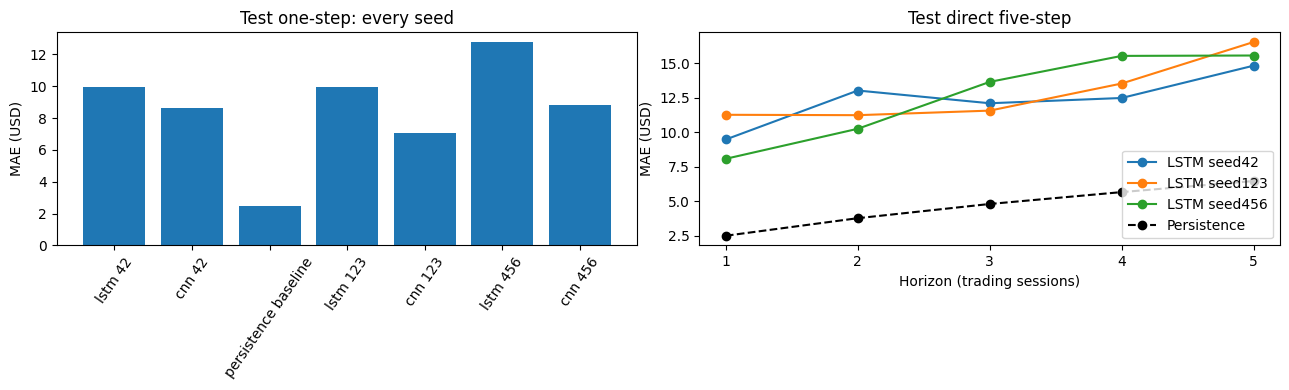

Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item5_20261126T172135216078Z
Next: mục6 phân tích lỗi và giới hạn; giữ nguyên cấu hình đã đánh giá.


In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
test_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
test_pointer=json.loads((test_root/'logs/audit/tv6_item5_latest.json').read_text())
test_folder=(test_root/test_pointer['evidence']).parent
test_summary=json.loads((test_folder/'summary.json').read_text())
test_ledger=json.loads((test_folder/'execution.json').read_text())
assert test_summary['passed'] and test_summary['test_performance_evaluated']
assert test_ledger['status']=='completed' and not test_summary['tuned_on_test']
for name,sha in test_summary['source_hashes'].items():
    assert hashlib.sha256((test_root/name).read_bytes()).hexdigest()==sha,name
test_metrics=pd.read_csv(test_folder/'metrics.csv')
test_aggregates=pd.read_csv(test_folder/'aggregates.csv')
assert len(test_metrics)==31 and len(test_aggregates)==8
display(pd.DataFrame([{k:test_summary[k] for k in ['models','prediction_rows','metric_rows','aggregate_rows','independent_metric_check','baseline_raw_last_check']}]))
display(test_metrics)
display(test_aggregates)
fig,axes=plt.subplots(1,2,figsize=(13,4))
one=test_metrics[test_metrics.forecast_length==1].copy()
one['label']=one.method+' '+one.seed.fillna(0).astype(int).astype(str).replace('0','baseline')
axes[0].bar(one.label,one.mae_usd)
axes[0].tick_params(axis='x',rotation=55)
axes[0].set(title='Test one-step: every seed',ylabel='MAE (USD)')
for seed,g in test_metrics[(test_metrics.forecast_length==5)&(test_metrics.method=='lstm')&(test_metrics.metric_scope=='per_horizon')].groupby('seed'):
    axes[1].plot(g.horizon_step,g.mae_usd,marker='o',label=f'LSTM seed{int(seed)}')
base=test_metrics[(test_metrics.forecast_length==5)&(test_metrics.method=='persistence')&(test_metrics.metric_scope=='per_horizon')]
axes[1].plot(base.horizon_step,base.mae_usd,'k--o',label='Persistence')
axes[1].set(title='Test direct five-step',xlabel='Horizon (trading sessions)',ylabel='MAE (USD)',xticks=[1,2,3,4,5])
axes[1].legend()
fig.tight_layout()
fig.savefig(test_folder/'test_metrics.png',dpi=150)
plt.show()
print('Evidence:',test_folder)
print('Next: mục6 phân tích lỗi và giới hạn; giữ nguyên cấu hình đã đánh giá.')

### Kiểm lại nguyên nhân persistence thắng — phân tích sau test

        Không train/tune hoặc chạy forward mới. Đọc prediction đã lưu, đối chiếu raw snapshot và phân nhóm theo giá origin vượt mức tối đa train. Các bảng dưới giữ riêng từng seed, không coi ba seed là ba phiên độc lập.

        Train có giá tối đa177,65USD, test tối đa285,20USD;91,04% giá test vượt mức tối đa train. LSTM/CNN một bước có bias âm rõ: thường dự báo thấp hơn actual. Đây là bằng chứng phù hợp với hạn chế ngoại suy mức giá; không phải chứng minh duy nhất về nguyên nhân, không tự kết luận gate saturation hay overfitting.

        Cơ chế sai số được kiểm bằng đẳng thức: đặt Δ=actual−origin, a=prediction−origin; MSE(model)=E[Δ²]+E[a²]−2E[aΔ]. Persistence có a=0. Trên test này, phần điều chỉnh của mạng làm tăng MSE thay vì cải thiện baseline. Scaler không clip giá; model hiện dự báo mức giá trực tiếp, không có đường cộng lại last price bắt buộc. Các thay đổi mô hình chỉ là giả thuyết nghiên cứu tương lai, chưa triển khai/tuning trên test.

,split,rows,minimum,maximum,mean,fraction_prices_above_train_max
0,train,2014,20.532551,177.651413,70.088454,0.000000
1,validation,250,122.734352,195.575211,169.918846,0.344000
2,test,502,163.096695,285.196411,217.998269,0.910359


,method,seed,samples,mae,bias,underprediction_fraction,mean_predicted_change,mean_actual_change
0,cnn,42,502,8.603183,-7.767594,0.862550,-7.606539e+00,0.161055
5,cnn,123,502,7.055796,-5.847374,0.818725,-5.686319e+00,0.161055
10,cnn,456,502,8.828708,-7.475495,0.810757,-7.314440e+00,0.161055
15,lstm,42,502,9.977535,-9.099803,0.850598,-8.938748e+00,0.161055
20,lstm,123,502,9.961957,-9.207472,0.864542,-9.046417e+00,0.161055
25,lstm,456,502,12.749535,-12.290303,0.926295,-1.212925e+01,0.161055
45,persistence,-1,502,2.476989,-0.161055,0.543825,-7.926373e-16,0.161055


,method,seed,segment,samples,mae,baseline_mae_same_rows
1,cnn,42,origin_within_train_max,45,2.968009,2.759240
2,cnn,42,origin_above_train_max,457,9.158068,2.449197
6,cnn,123,origin_within_train_max,45,2.765079,2.759240
7,cnn,123,origin_above_train_max,457,7.478295,2.449197
11,cnn,456,origin_within_train_max,45,3.085044,2.759240
12,cnn,456,origin_above_train_max,457,9.394277,2.449197
16,lstm,42,origin_within_train_max,45,2.965885,2.759240
17,lstm,42,origin_above_train_max,457,10.667960,2.449197
21,lstm,123,origin_within_train_max,45,3.079218,2.759240
22,lstm,123,origin_above_train_max,457,10.639688,2.449197


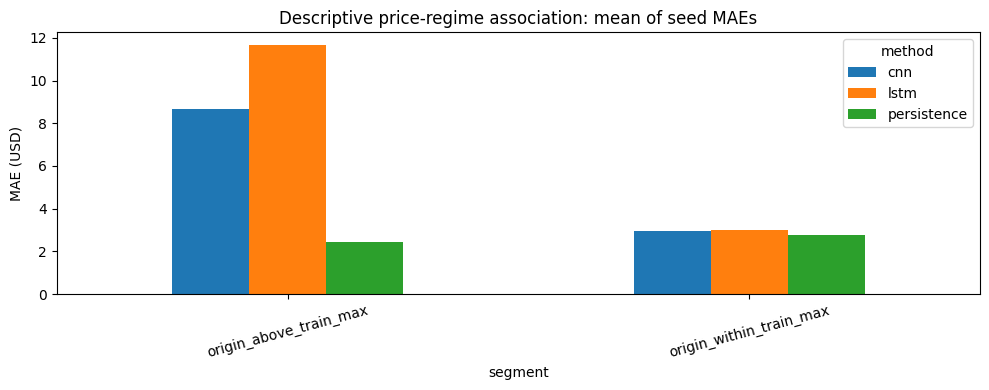

Association is not causal proof. No retraining or test-based selection.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
gap_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
gap_pointer=json.loads((gap_root/'logs/audit/tv6_item5_latest.json').read_text())
gap_folder=(gap_root/gap_pointer['evidence']).parent/'gap_diagnosis'
gap_receipt=json.loads((gap_folder/'summary.json').read_text())
assert gap_receipt['passed'] and not gap_receipt['new_inference']
display(pd.read_csv(gap_folder/'price_distribution.csv'))
gap_table=pd.read_csv(gap_folder/'diagnosis_by_seed.csv')
gap_one=gap_table[(gap_table.forecast_length==1)&(gap_table.segment=='all')]
display(gap_one[['method','seed','samples','mae','bias','underprediction_fraction','mean_predicted_change','mean_actual_change']])
gap_segments=gap_table[(gap_table.forecast_length==1)&gap_table.segment.str.startswith('origin_')]
display(gap_segments[['method','seed','segment','samples','mae','baseline_mae_same_rows']])
gap_plot=gap_segments.groupby(['segment','method']).mae.mean().unstack('method')
ax=gap_plot.plot.bar(figsize=(10,4),rot=15)
ax.set(ylabel='MAE (USD)',title='Descriptive price-regime association: mean of seed MAEs')
plt.tight_layout()
plt.show()
print('Association is not causal proof. No retraining or test-based selection.')

### Thử nghiệm cải tiến riêng: residual theo giá origin

        Theo yêu cầu thử sửa mô hình sau khi đã xem test: dùng X=(history−origin)/scale_train và target=(future−origin)/scale_train. Decode giá=origin+scale_train*output. LSTM h1, CNN h1 và LSTM direct h5 giữ core architecture/float64; head residual khởi tạo0 để bắt đầu bằng persistence. Đây là gói thay đổi, chưa tách ablation từng yếu tố.

        Hai fold: train2015–2021→validation2022; train2015–2022→validation2023. Scaler fit giá train riêng mỗi fold. Mọi target h5 cùng split.36runs gồm2 biểu diễn×2fold×3task×3seed, cùng Adam/MSE/lr0.001/batch32/max100/patience10. Control được train lại trên cùng mẫu với residual, không phải sao chép điểm test hoặc coi giống hệt run common60 cũ.

        Chỉ đánh giá development; không chạy testforward mới, không tuning/chọn seed theo test, không thay catalog/releasev1. Bảng ghi đủ mọi seed và persistence. Run All chỉ đọc kết quả đã lưu; training ở CLI scripts/run_tv6_residual_development.py.

,passed,runs_verified,paired_cohorts,raw_actuals_verified,baseline_origin_verified,independent_metrics_and_aggregates,scaler_train_only_verified,checkpoint_hashes_and_best_epochs_verified,untouched_test_claim,test_inference_performed
0,True,36,6,True,True,True,True,True,False,False


,validation_year,task,representation,seed,horizon_step,scope,samples,error_count,mae_usd,rmse_usd,bias_usd
0,2022,lstm_h1,persistence,NaN,1.0,per_horizon,251,251,2.602120,3.342642,0.182323
1,2022,lstm_h1,absolute-price-control,42.0,1.0,per_horizon,251,251,3.713195,4.495111,0.461556
2,2022,lstm_h1,absolute-price-control,123.0,1.0,per_horizon,251,251,3.305072,3.995568,-0.015341
3,2022,lstm_h1,absolute-price-control,456.0,1.0,per_horizon,251,251,5.195273,6.124695,0.061716
4,2022,lstm_h1,origin-centered-price-delta-v1,42.0,1.0,per_horizon,251,251,2.600649,3.341195,0.154766
5,2022,lstm_h1,origin-centered-price-delta-v1,123.0,1.0,per_horizon,251,251,2.591422,3.313741,0.332641
6,2022,lstm_h1,origin-centered-price-delta-v1,456.0,1.0,per_horizon,251,251,2.598853,3.326087,0.436431
7,2022,cnn_h1,persistence,NaN,1.0,per_horizon,251,251,2.602120,3.342642,0.182323
8,2022,cnn_h1,absolute-price-control,42.0,1.0,per_horizon,251,251,3.176808,3.939370,-0.149810
9,2022,cnn_h1,absolute-price-control,123.0,1.0,per_horizon,251,251,4.440853,5.329077,-1.179933


,validation_year,task,representation,scope,horizon_step,mae_mean,mae_std,rmse_mean,rmse_std,bias_mean,seeds
0,2022,cnn_h1,absolute-price-control,per_horizon,1.0,3.895882,0.649759,4.710505,0.707304,-0.411751,3
1,2022,cnn_h1,origin-centered-price-delta-v1,per_horizon,1.0,2.593409,0.010646,3.322922,0.029836,0.157238,3
2,2022,lstm_h1,absolute-price-control,per_horizon,1.0,4.071180,0.994650,4.871791,1.113424,0.169310,3
3,2022,lstm_h1,origin-centered-price-delta-v1,per_horizon,1.0,2.596975,0.004892,3.327008,0.013750,0.307946,3
4,2022,lstm_h5,absolute-price-control,overall,NaN,5.486088,0.329376,6.640461,0.230536,0.513148,3
10,2022,lstm_h5,origin-centered-price-delta-v1,overall,NaN,4.323299,0.006533,5.510879,0.007466,0.638174,3
16,2023,cnn_h1,absolute-price-control,per_horizon,1.0,2.160442,0.140421,2.773064,0.186254,0.240979,3
17,2023,cnn_h1,origin-centered-price-delta-v1,per_horizon,1.0,1.620033,0.000655,2.106200,0.000295,-0.042932,3
18,2023,lstm_h1,absolute-price-control,per_horizon,1.0,2.801693,0.862486,3.414598,1.018335,-0.951927,3
19,2023,lstm_h1,origin-centered-price-delta-v1,per_horizon,1.0,1.619409,0.000959,2.106283,0.000550,-0.025826,3


,validation_year,task,absolute_mae,residual_mae,baseline_mae,mae_improvement_pct,absolute_rmse,residual_rmse,baseline_rmse
0,2022,cnn_h1,3.895882,2.593409,2.602120,33.432051,4.710505,3.322922,3.342642
1,2022,lstm_h1,4.071180,2.596975,2.602120,36.210760,4.871791,3.327008,3.342642
2,2022,lstm_h5,5.486088,4.323299,4.313107,21.195234,6.640461,5.510879,5.499468
3,2023,cnn_h1,2.160442,1.620033,1.636779,25.013809,2.773064,2.106200,2.120593
4,2023,lstm_h1,2.801693,1.619409,1.636779,42.198895,3.414598,2.106283,2.120593
5,2023,lstm_h5,4.153028,2.931102,2.984996,29.422527,5.044827,3.841833,3.903600


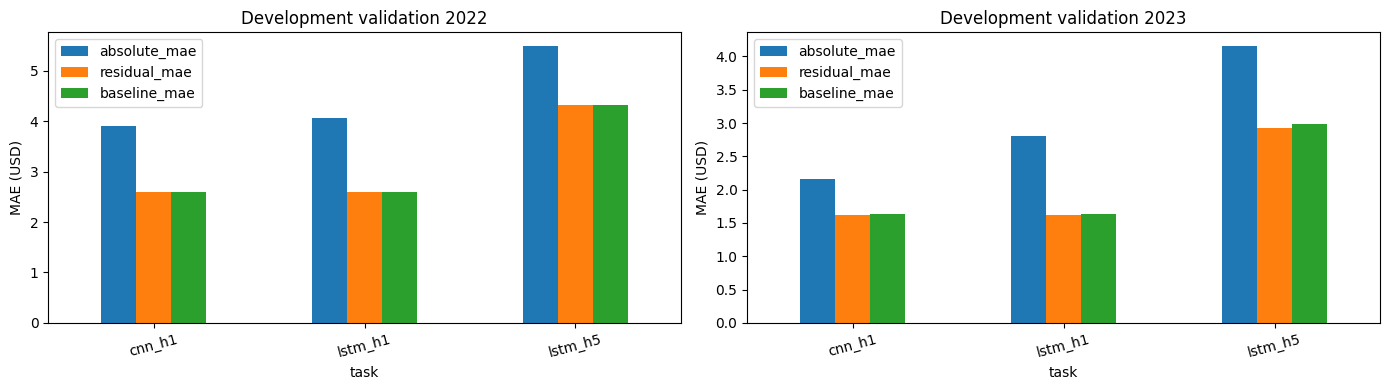

Development only: no new independent held-out claim. Original test results remain unchanged.


In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
dev_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
dev_pointer=json.loads((dev_root/'logs/audit/tv6_residual_development_latest.json').read_text())
dev_folder=(dev_root/dev_pointer['evidence']).parent
dev_receipt=json.loads((dev_folder/'summary.json').read_text())
assert dev_receipt['passed'] and dev_receipt['runs_completed']==36
assert dev_receipt['post_test_development'] and not dev_receipt['test_inference_performed']
dev_audit=json.loads((dev_folder/'independent_audit.json').read_text())
assert dev_audit['passed'] and dev_audit['runs_verified']==36
for name,sha in dev_audit['result_hashes'].items():
    assert hashlib.sha256((dev_folder/name).read_bytes()).hexdigest()==sha,name
display(pd.DataFrame([{k:v for k,v in dev_audit.items() if k!='result_hashes'}]))
for name,sha in dev_receipt['source_hashes'].items():
    assert hashlib.sha256((dev_root/name).read_bytes()).hexdigest()==sha,name
dev_metrics=pd.read_csv(dev_folder/'metrics.csv')
dev_aggregate=pd.read_csv(dev_folder/'aggregates.csv')
dev_primary=dev_metrics[((dev_metrics.task!='lstm_h5')|(dev_metrics.scope=='overall'))]
display(dev_primary)
dev_primary_aggregate=dev_aggregate[(dev_aggregate.task!='lstm_h5')|(dev_aggregate.scope=='overall')]
display(dev_primary_aggregate)
dev_compare=[]
for (year,task),g in dev_primary.groupby(['validation_year','task']):
    absolute=g[g.representation=='absolute-price-control'];residual=g[g.representation=='origin-centered-price-delta-v1'];base=g[g.representation=='persistence']
    assert len(absolute)==3 and len(residual)==3 and len(base)==1
    dev_compare.append(dict(validation_year=year,task=task,absolute_mae=absolute.mae_usd.mean(),residual_mae=residual.mae_usd.mean(),
        baseline_mae=base.mae_usd.iloc[0],mae_improvement_pct=100*(1-residual.mae_usd.mean()/absolute.mae_usd.mean()),
        absolute_rmse=absolute.rmse_usd.mean(),residual_rmse=residual.rmse_usd.mean(),baseline_rmse=base.rmse_usd.iloc[0]))
dev_comparison=pd.DataFrame(dev_compare)
display(dev_comparison)
dev_comparison.to_csv(dev_folder/'comparison.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,(year,g) in zip(axes,dev_comparison.groupby('validation_year')):
    g.set_index('task')[['absolute_mae','residual_mae','baseline_mae']].plot.bar(ax=ax,rot=15)
    ax.set(title=f'Development validation {year}',ylabel='MAE (USD)')
fig.tight_layout();fig.savefig(dev_folder/'development_comparison.png',dpi=140);plt.show()
print('Development only: no new independent held-out claim. Original test results remain unchanged.')

### Kiểm chứng huấn luyện, checkpoint và chi tiết horizon

        Đồ thị loss dưới là các run thật trên fold2023, hiển thị cả ba seed mỗi nhóm. Train loss được tính online ở chế độ train; validation ở eval, nên không dùng chênh lệch đơn lẻ để kết luận overfitting. Checkpoint best validation được restore và lưu file mới, reload kiểm dự đoán. Không lựa seed tốt nhất để công bố. H5 báo đủ từng horizon và overall trong bảng.

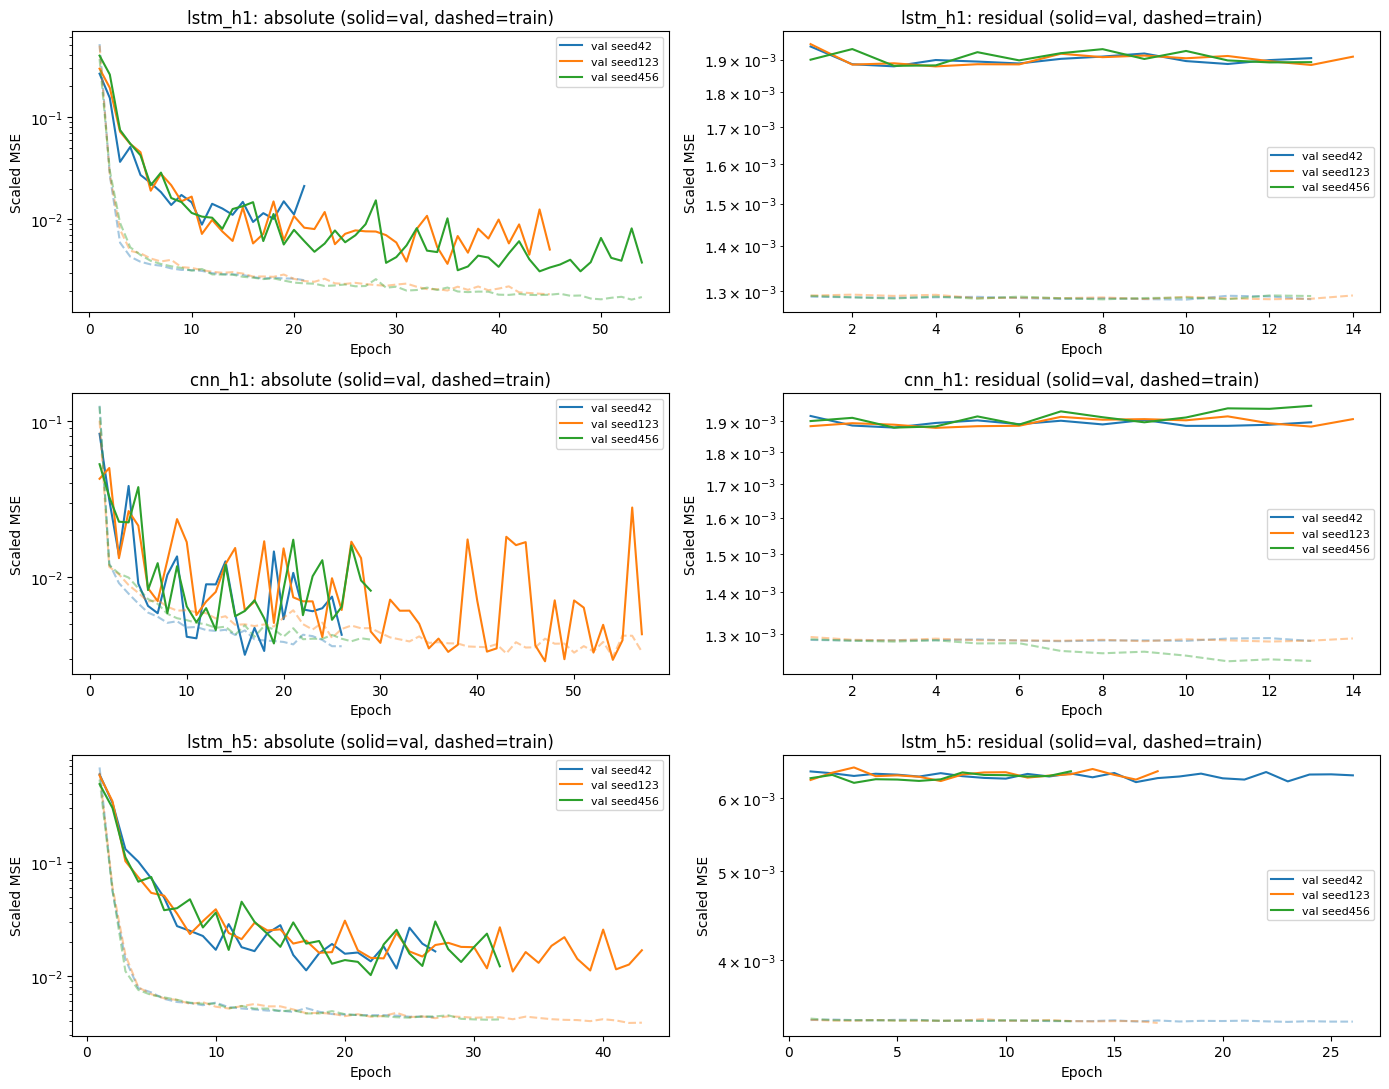

,validation_year,task,representation,scope,horizon_step,mae_mean,mae_std,rmse_mean,rmse_std,bias_mean,seeds
4,2022,lstm_h5,absolute-price-control,overall,NaN,5.486088,0.329376,6.640461,0.230536,0.513148,3
5,2022,lstm_h5,absolute-price-control,per_horizon,1.0,4.056630,0.218446,4.958744,0.220500,-0.387903,3
6,2022,lstm_h5,absolute-price-control,per_horizon,2.0,4.800435,0.294605,5.856422,0.185852,0.033749,3
7,2022,lstm_h5,absolute-price-control,per_horizon,3.0,5.559534,0.268461,6.648219,0.180907,0.714834,3
8,2022,lstm_h5,absolute-price-control,per_horizon,4.0,6.196091,0.478295,7.329019,0.350922,0.986876,3
9,2022,lstm_h5,absolute-price-control,per_horizon,5.0,6.817748,0.624844,7.970504,0.501027,1.218182,3
10,2022,lstm_h5,origin-centered-price-delta-v1,overall,NaN,4.323299,0.006533,5.510879,0.007466,0.638174,3
11,2022,lstm_h5,origin-centered-price-delta-v1,per_horizon,1.0,2.603367,0.003290,3.348085,0.002224,0.155438,3
12,2022,lstm_h5,origin-centered-price-delta-v1,per_horizon,2.0,3.814064,0.000475,4.696380,0.000530,0.412602,3
13,2022,lstm_h5,origin-centered-price-delta-v1,per_horizon,3.0,4.438245,0.009089,5.579609,0.012231,0.631284,3


,validation_year,task,representation,seed,best_epoch,epochs,seconds
0,2022,lstm_h1,absolute-price-control,42,41,51,53.558393
1,2022,lstm_h1,absolute-price-control,123,58,68,41.158266
2,2022,lstm_h1,absolute-price-control,456,6,16,9.266832
3,2022,lstm_h1,origin-centered-price-delta-v1,42,1,11,17.497676
4,2022,lstm_h1,origin-centered-price-delta-v1,123,22,32,32.231715
5,2022,lstm_h1,origin-centered-price-delta-v1,456,51,61,59.361345
6,2022,cnn_h1,absolute-price-control,42,54,64,26.886374
7,2022,cnn_h1,absolute-price-control,123,18,28,8.181662
8,2022,cnn_h1,absolute-price-control,456,25,35,9.404105
9,2022,cnn_h1,origin-centered-price-delta-v1,42,1,11,2.793420


Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_residual_development_20261127T012509759710Z


In [2]:
fig,axes=plt.subplots(3,2,figsize=(14,11))
for i,task in enumerate(['lstm_h1','cnn_h1','lstm_h5']):
    for j,(tag,representation) in enumerate([('absolute','absolute-price-control'),('residual','origin-centered-price-delta-v1')]):
        ax=axes[i,j]
        for seed in [42,123,456]:
            history=pd.read_csv(dev_folder/f'2023_{task}_{tag}_seed{seed}'/'epoch_logs.csv')
            line=ax.plot(history.epoch,history.val_loss,label=f'val seed{seed}')[0]
            ax.plot(history.epoch,history.train_loss,'--',alpha=.4,color=line.get_color())
        ax.set(title=f'{task}: {tag} (solid=val, dashed=train)',xlabel='Epoch',ylabel='Scaled MSE',yscale='log')
        ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(dev_folder/'training_histories.png',dpi=140);plt.show()
display(dev_aggregate[dev_aggregate.task=='lstm_h5'])
display(pd.DataFrame(dev_receipt['runs'])[['validation_year','task','representation','seed','best_epoch','epochs','seconds']])
print('Evidence:',dev_folder)

## 6. Phân tích lỗi và giá trị của lịch sử đối với LSTM

        Nghiệm thu phần phân tích, chưa sửa/train tiếp. Dùng lỗi test v1 đã lưu và12checkpoint residual LSTM hiện có trên development2022/2023. Forward mới chỉ trên validation để kiểm độ nhạy; không forward test mới, không update weights/scaler hoặc chọn seed.

        Các đối chứng giữ nguyên origin: flat (30giá đều bằng giá cuối), đảo/xáo trộn29giá trước với RNG cố định. Chúng là input nhân tạo, có thể ngoài phân phối; dùng để quan sát độ nhạy, không phải bằng chứng nhân quả hoặc phương án chọn model theo điểm tốt nhất.

        Phát hiện trọng tâm: LSTM residual h1 trên validation2023 dự báo gần như một mức điều chỉnh hằng số. Bỏ biến động lịch sử bằng flat chỉ đổi dự báo trung bình0,0037USD; MAE1,6194→1,6196, RMSE flat còn hơi thấp hơn. Đảo/xáo trộn không làm lỗi tăng nhất quán. Đây chưa là bằng chứng học được quy luật30phiên mạnh. Fold2022 h1 nhạy hơn; không khái quát thành mọi LSTM đều bỏ qua lịch sử.

        Những cải thiện trước đó vẫn có thật trên development, nhưng phần lợi thế so persistence cần đối chiếu một tham chiếu drift hằng số và ablation có kiểm soát trước khi quy cho khả năng học chuỗi. Chưa thử sửa các điểm này trong mục6.

,passed,official_metric_rows_verified,summary_rows,partition_counts_verified,probe_metric_rows_verified,probe_prediction_rows,flat_per_horizon_constant_verified,source_hashes_unchanged,training_performed,new_test_inference
0,True,31,73,True,168,35592,True,True,False,False


,validation_year,forecast_length,seed,control,mae_usd,rmse_usd,mean_adjustment_usd,std_adjustment_usd,mean_abs_change_from_real_usd
0,2022,1,42,real,2.600649,3.341195,-0.027557,7.818593e-04,0.000000
1,2022,1,42,flat,2.600688,3.341247,-0.027662,1.779611e-15,0.000649
2,2022,1,42,reverse_prefix,2.600491,3.341164,-0.027265,2.015975e-03,0.001536
3,2022,1,42,shuffle_prefix,2.600587,3.341171,-0.027377,1.373389e-03,0.000884
4,2022,1,123,real,2.591422,3.313741,0.150318,4.339756e-01,0.000000
5,2022,1,123,flat,2.599267,3.340090,-0.055088,0.000000e+00,0.266759
6,2022,1,123,reverse_prefix,2.706814,3.502440,0.647176,1.062859e+00,0.648542
7,2022,1,123,shuffle_prefix,2.624501,3.355220,0.364448,7.513148e-01,0.326155
8,2022,1,456,real,2.598853,3.326087,0.254108,4.793916e-01,0.000000
9,2022,1,456,flat,2.605359,3.345742,0.050005,0.000000e+00,0.255016


mae_usd  rmse_usd  \
validation_year forecast_length control                              
2022            1               flat            2.601771  3.342360   
                                real            2.596975  3.327008   
                                reverse_prefix  2.694281  3.484827   
                                shuffle_prefix  2.622649  3.362310   
                5               flat            4.323406  5.511422   
                                real            4.323299  5.510879   
                                reverse_prefix  4.321331  5.510216   
                                shuffle_prefix  4.322660  5.510575   
2023            1               flat            1.619649  2.106067   
                                real            1.619409  2.106283   
                                reverse_prefix  1.617603  2.105731   
                                shuffle_prefix  1.618488  2.105813   
                5               flat            2.928293  3.839706   
                                real            2.931102  3.841833   
                                reverse_prefix  2.926970  3.842448   
                                shuffle_prefix  2.927678  3.838641   

                                                mean_abs_change_from_real_usd  
validation_year forecast_length control                                        
2022            1               flat                                 0.174141  
                                real                                 0.000000  
                                reverse_prefix                       0.468700  
                                shuffle_prefix                       0.229482  
                5               flat                                 0.015043  
                                real                                 0.000000  
                                reverse_prefix                       0.052005  
                                shuffle_prefix                       0.031608  
2023            1               flat                                 0.003708  
                                real                                 0.000000  
                                reverse_prefix                       0.017801  
                                shuffle_prefix                       0.009611  
                5               flat                                 0.034116  
                                real                                 0.000000  
                                reverse_prefix                       0.149239  
                                shuffle_prefix                       0.082811

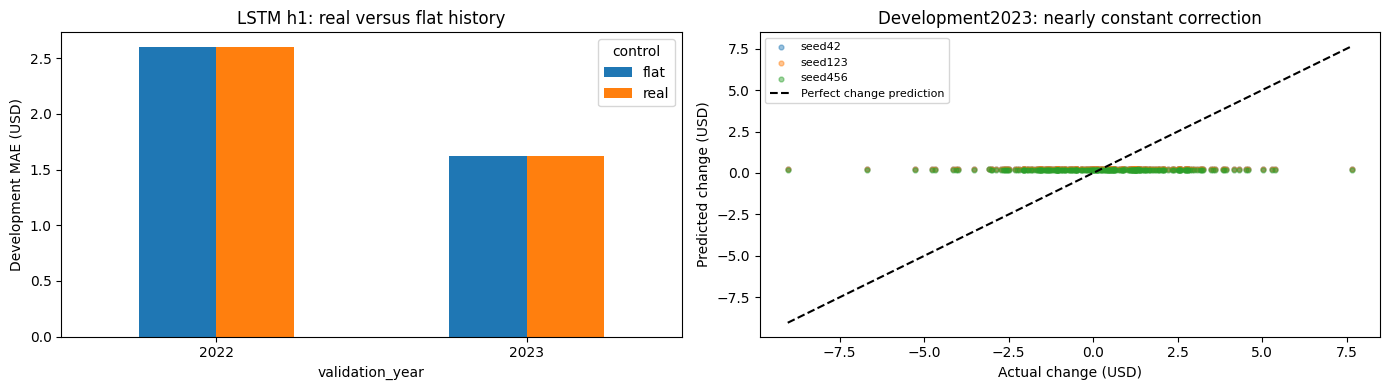

All3seeds retained. Each session repeats across seeds; no significance/causal claim.


In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
item6_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
item6_pointer=json.loads((item6_root/'logs/audit/tv6_item6_latest.json').read_text())
item6_folder=(item6_root/item6_pointer['evidence']).parent
item6_receipt=json.loads((item6_folder/'summary.json').read_text())
item6_audit=json.loads((item6_folder/'independent_audit.json').read_text())
assert item6_receipt['passed'] and item6_audit['passed']
assert not item6_receipt['training_performed'] and not item6_receipt['new_test_inference']
for name,sha in item6_receipt['source_hashes'].items():
    assert hashlib.sha256((item6_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in item6_audit['result_hashes'].items():
    assert hashlib.sha256((item6_folder/name).read_bytes()).hexdigest()==sha,name
display(pd.DataFrame([{k:v for k,v in item6_audit.items() if k!='result_hashes'}]))
item6_probes=pd.read_csv(item6_folder/'history_probes.csv')
item6_primary=item6_probes[(item6_probes.forecast_length==1)|(item6_probes.metric_scope=='overall')]
display(item6_primary[['validation_year','forecast_length','seed','control','mae_usd','rmse_usd','mean_adjustment_usd','std_adjustment_usd','mean_abs_change_from_real_usd']])
display(item6_primary.groupby(['validation_year','forecast_length','control'])[['mae_usd','rmse_usd','mean_abs_change_from_real_usd']].mean())
item6_predictions=pd.read_csv(item6_folder/'history_probe_predictions.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4))
item6_probes[(item6_probes.forecast_length==1)&item6_probes.control.isin(['real','flat'])].groupby(['validation_year','control']).mae_usd.mean().unstack('control').plot.bar(ax=axes[0],rot=0)
axes[0].set(title='LSTM h1: real versus flat history',ylabel='Development MAE (USD)')
scatter=item6_predictions[(item6_predictions.validation_year==2023)&(item6_predictions.forecast_length==1)&(item6_predictions.control=='real')]
for seed,g in scatter.groupby('seed'):
    axes[1].scatter(g.actual_price-g.origin_price,g.predicted_price-g.origin_price,s=12,alpha=.45,label=f'seed{seed}')
lo=(scatter.actual_price-scatter.origin_price).min();hi=(scatter.actual_price-scatter.origin_price).max()
axes[1].plot([lo,hi],[lo,hi],'k--',label='Perfect change prediction')
axes[1].set(title='Development2023: nearly constant correction',xlabel='Actual change (USD)',ylabel='Predicted change (USD)')
axes[1].legend(fontsize=8)
fig.tight_layout();fig.savefig(item6_folder/'history_diagnostics.png',dpi=140);plt.show()
print('All3seeds retained. Each session repeats across seeds; no significance/causal claim.')

### Lỗi theo thời gian, horizon, stress và các vấn đề cần xử lý

        Test v1: LSTM h1 lỗi lớn tập trung cuối2025, không chỉ ở những phiên biến động lớn. Trên482phiên không vượt ngưỡng95% biến động tương đối của train, MAE LSTM trung bình3seed vẫn10,80USD so persistence2,11USD. Không được loại outlier để cải thiện bảng điểm.

        Residual development: stress dùng actual tương lai để gán nhãn hồi cứu, không phải feature dự báo. Validation2023 h1 chỉ có2phiên stress theo ngưỡngtrain, chưa đủ kết luận về khả năng chống shock. H5 phải xem từnghorizon; windows chồng lấn không là các quan sát độc lập.

        Báo cáo vấn đề: (1)v1 hạn chế ngoại suy/bias âm; (2)residual chủ yếu hiệu chỉnh gần hằng số ởfold2023; (3)lợi thế baseline nhỏ/không đồng đều giữa2fold vàstress; (4)chưa có test độc lập cho sửa sau test; (5)gói cải tiến còn nhiều yếu tố đồng thời, cầnablation để quy nguyên nhân. Không kết luận gate saturation/vanishing gradient hay tăngepoch sẽ sửa được vì chưa có phép đo. Dừng ở báo cáo, chưa train/fix hoặc sangrelease/API.

,cohort,representation,method,seed,forecast_length,horizon_step,metric_scope,year,samples,error_count,...,baseline_rmse_usd,bias_usd,underprediction_fraction,p95_abs_error_usd,max_abs_error_usd,mean_adjustment_usd,std_adjustment_usd,std_actual_change_usd,mean_abs_adjustment_usd,mse_skill_vs_persistence
0,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,2024,252,252,...,2.882309,-5.479928,0.781746,16.751052,23.609131,-5.248339,5.672366,2.872990,5.691379,-7.443523
1,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,2025,250,250,...,4.294722,-12.748637,0.920000,32.746175,40.670842,-12.658681,10.543390,4.293779,12.888323,-14.729120
6,official_test_2024_2025,absolute-price-v1,lstm,123.0,1,1.0,per_horizon,2024,252,252,...,2.882309,-5.971572,0.789683,16.337651,22.278353,-5.739983,5.587058,2.872990,6.152082,-8.023548
7,official_test_2024_2025,absolute-price-v1,lstm,123.0,1,1.0,per_horizon,2025,250,250,...,4.294722,-12.469259,0.940000,28.660894,36.056337,-12.379303,8.653978,4.293779,12.544519,-12.436027
10,official_test_2024_2025,absolute-price-v1,lstm,456.0,1,1.0,per_horizon,2024,252,252,...,2.882309,-8.343977,0.884921,20.398933,27.371721,-8.112388,6.552794,2.872990,8.259341,-13.501404
11,official_test_2024_2025,absolute-price-v1,lstm,456.0,1,1.0,per_horizon,2025,250,250,...,4.294722,-16.268199,0.968000,35.575166,43.677357,-16.178243,10.546246,4.293779,16.318025,-20.284536
24,official_test_2024_2025,absolute-price-v1,lstm,42.0,5,NaN,overall,2024,252,1250,...,5.060522,-7.746892,0.827200,21.220392,31.369550,-6.941660,6.058802,4.996047,7.173086,-3.727145
25,official_test_2024_2025,absolute-price-v1,lstm,42.0,5,NaN,overall,2025,250,1240,...,8.032535,-14.872085,0.918548,35.856999,49.274432,-14.618801,10.207114,8.028540,14.725783,-4.865054
48,official_test_2024_2025,absolute-price-v1,lstm,123.0,5,NaN,overall,2024,252,1250,...,5.060522,-8.162351,0.830400,22.391618,34.266224,-7.357119,6.372501,4.996047,7.583419,-4.155123
49,official_test_2024_2025,absolute-price-v1,lstm,123.0,5,NaN,overall,2025,250,1240,...,8.032535,-15.472098,0.924194,36.994345,52.366101,-15.218814,10.473894,8.028540,15.321202,-5.230756


,cohort,representation,method,seed,forecast_length,horizon_step,metric_scope,stress_group,samples,error_count,...,baseline_rmse_usd,bias_usd,underprediction_fraction,p95_abs_error_usd,max_abs_error_usd,mean_adjustment_usd,std_adjustment_usd,std_actual_change_usd,mean_abs_adjustment_usd,mse_skill_vs_persistence
0,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,train_p95_exceedance,20,20,...,12.174526,-6.431011,0.700000,28.561695,29.739392,-5.071686,7.386074,12.098401,6.873455,-0.494101
1,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,within_train_p95,482,482,...,2.785677,-9.210541,0.856846,30.314248,40.670842,-9.099207,9.266453,2.783451,9.375185,-21.933141
6,official_test_2024_2025,absolute-price-v1,lstm,123.0,1,1.0,per_horizon,train_p95_exceedance,20,20,...,12.174526,-7.457548,0.700000,28.374162,28.874580,-6.098223,7.155007,12.098401,7.467540,-0.563899
7,official_test_2024_2025,absolute-price-v1,lstm,123.0,1,1.0,per_horizon,within_train_p95,482,482,...,2.785677,-9.280083,0.871369,26.430848,36.056337,-9.168748,8.008833,2.783451,9.413078,-19.375493
10,official_test_2024_2025,absolute-price-v1,lstm,456.0,1,1.0,per_horizon,train_p95_exceedance,20,20,...,12.174526,-9.641271,0.700000,32.466233,33.677863,-8.281946,8.261326,12.098401,9.441145,-0.896397
11,official_test_2024_2025,absolute-price-v1,lstm,456.0,1,1.0,per_horizon,within_train_p95,482,482,...,2.785677,-12.400221,0.935685,33.570744,43.677357,-12.288887,9.674991,2.783451,12.390119,-31.853894
24,official_test_2024_2025,absolute-price-v1,lstm,42.0,5,NaN,overall,train_p95_exceedance,50,107,...,20.663153,-9.727245,0.682243,33.542544,41.064193,-6.469447,6.092566,20.404721,7.274517,-0.088134
25,official_test_2024_2025,absolute-price-v1,lstm,42.0,5,NaN,overall,within_train_p95,493,2383,...,5.275958,-11.365584,0.881242,32.551946,49.274432,-10.957683,9.291520,5.260166,11.098596,-7.605933
48,official_test_2024_2025,absolute-price-v1,lstm,123.0,5,NaN,overall,train_p95_exceedance,50,107,...,20.663153,-10.147742,0.682243,34.488063,40.060967,-6.889944,6.440979,20.404721,7.703988,-0.111690
49,official_test_2024_2025,absolute-price-v1,lstm,123.0,5,NaN,overall,within_train_p95,493,2383,...,5.275958,-11.876850,0.885858,33.305800,52.366101,-11.468949,9.579485,5.260166,11.604380,-8.237335


,cohort,representation,method,seed,forecast_length,horizon_step,metric_scope,sample_id,forecast_origin,target_date,actual_price,predicted_price,abs_error_usd,actual_horizon_step
0,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-12-01,2025-12-02,285.196411,244.525569,40.670842,1
1,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-28,2025-12-01,282.117157,243.457021,38.660136,1
2,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-12-02,2025-12-03,283.163513,245.597074,37.566439,1
3,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-26,2025-11-28,277.881927,242.998677,34.883251,1
4,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-21,2025-11-24,274.962067,240.338084,34.623982,1
5,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-12-09,2025-12-10,277.812134,243.535061,34.277072,1
6,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-24,2025-11-25,276.008392,241.754533,34.253859,1
7,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-10,2025-11-11,274.294403,240.088343,34.206060,1
8,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-12-03,2025-12-04,279.725464,245.644295,34.081169,1
9,official_test_2024_2025,absolute-price-v1,lstm,42.0,1,1.0,per_horizon,aapl_2015_2025_acq_20261119T141302002415Z:lb30...,2025-11-25,2025-11-26,276.586426,242.561078,34.025348,1


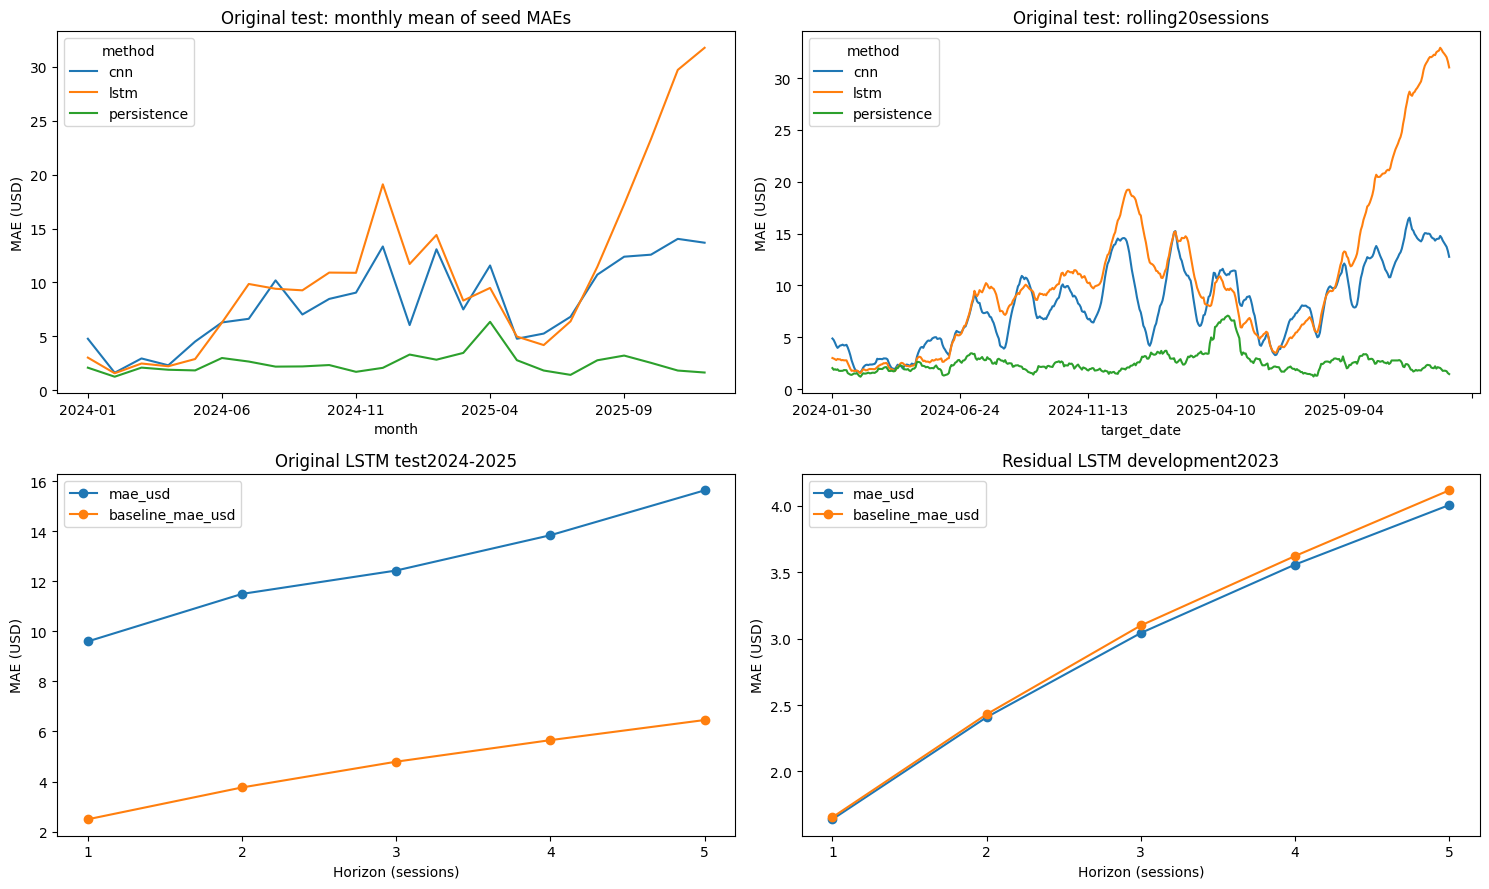

Different cohorts in lower panels; no direct test-versus-development performance comparison.
Item6 analysis complete. Model fixes remain for the next user-authorized task.
Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item6_20261127T015255603485Z


In [2]:
item6_summary=pd.read_csv(item6_folder/'summary.csv')
item6_monthly=pd.read_csv(item6_folder/'monthly.csv')
item6_yearly=pd.read_csv(item6_folder/'yearly.csv')
item6_stress=pd.read_csv(item6_folder/'stress.csv')
item6_largest=pd.read_csv(item6_folder/'largest.csv')
display(item6_yearly[(item6_yearly.method=='lstm')&((item6_yearly.forecast_length==1)|(item6_yearly.metric_scope=='overall'))])
display(item6_stress[(item6_stress.method=='lstm')&((item6_stress.forecast_length==1)|(item6_stress.metric_scope=='overall'))])
display(item6_largest[(item6_largest.cohort=='official_test_2024_2025')&(item6_largest.method=='lstm')&(item6_largest.forecast_length==1)])
fig,axes=plt.subplots(2,2,figsize=(15,9))
monthly=item6_monthly[(item6_monthly.cohort=='official_test_2024_2025')&(item6_monthly.forecast_length==1)]
monthly.groupby(['month','method']).mae_usd.mean().unstack('method').plot(ax=axes[0,0])
axes[0,0].set(title='Original test: monthly mean of seed MAEs',ylabel='MAE (USD)')
rolling=pd.read_csv(item6_folder/'rolling.csv')
rolling=rolling[(rolling.cohort=='official_test_2024_2025')&(rolling.forecast_length==1)]
rolling.groupby(['target_date','method']).mae_usd.mean().unstack('method').plot(ax=axes[0,1])
axes[0,1].set(title='Original test: rolling20sessions',ylabel='MAE (USD)')
for ax,cohort,title in [(axes[1,0],'official_test_2024_2025','Original LSTM test2024-2025'),(axes[1,1],'development_2023','Residual LSTM development2023')]:
    h=item6_summary[(item6_summary.cohort==cohort)&(item6_summary.forecast_length==5)&(item6_summary.method=='lstm')&(item6_summary.metric_scope=='per_horizon')]
    h.groupby('horizon_step')[['mae_usd','baseline_mae_usd']].mean().plot(ax=ax,marker='o')
    ax.set(title=title,xlabel='Horizon (sessions)',ylabel='MAE (USD)',xticks=[1,2,3,4,5])
fig.tight_layout();fig.savefig(item6_folder/'time_and_horizon_errors.png',dpi=140);plt.show()
print('Different cohorts in lower panels; no direct test-versus-development performance comparison.')
print('Item6 analysis complete. Model fixes remain for the next user-authorized task.')
print('Evidence:',item6_folder)

### Bước tiếp theo sau mục6: tham chiếu train-only và kiểm đường học

        Xử lý ưu tiên1 bằng phép kiểm có số liệu: tham chiếu origin+meanchange chỉ ước lượng từ các window train của từngfold, không dùngactual validation/test để ước lượng. Đây là diagnostic reference, không đổi persistence/protocol/releasev1.

        Trên cùng mẫu, LSTM residual tốt hơn train-meanchange ở cả hai fold nhưng mức lợi ích nhỏ; chưa chứng minh đó là lợi ích từ lịch sử vì kiểmflat trước đó vẫn gần tương đương. Không nhầm việc thắng một tham chiếu với chứng minh cơ chế học chuỗi.

        Gradient đo bằng MSE delta chuẩn hóa trên3batch train cố định first/middle/last32, đủ12checkpoint và3trạng thái: reconstructed init zerohead/defaulthead vàcheckpoint hiện có. Backward trên bản sao, không optimizerstep, không tạo model đã train mới hoặc chạy testforward. Đây là ảnh chụp gradient, không phải log toàn bộ quá trình train cũ.

,validation_year,forecast_length,method,seed,samples,mae_usd,rmse_usd,bias_usd
0,2022,1,persistence,NaN,251,2.602120,3.342642,0.182323
1,2022,1,train_mean_change,NaN,251,2.607913,3.348254,0.266070
2,2022,1,lstm_residual,42.0,251,2.600649,3.341195,0.154766
3,2022,1,lstm_residual,123.0,251,2.591422,3.313741,0.332641
4,2022,1,lstm_residual,456.0,251,2.598853,3.326087,0.436431
10,2022,5,persistence,NaN,247,4.313107,5.499468,0.568120
16,2022,5,train_mean_change,NaN,247,4.345204,5.538603,0.822694
22,2022,5,lstm_residual,42.0,247,4.315862,5.502301,0.562597
28,2022,5,lstm_residual,123.0,247,4.325918,5.514429,0.681171
34,2022,5,lstm_residual,456.0,247,4.328115,5.515908,0.670755


mae_usd  rmse_usd
validation_year forecast_length method                               
2022            1               lstm_residual      2.596975  3.327008
                                persistence        2.602120  3.342642
                                train_mean_change  2.607913  3.348254
                5               lstm_residual      4.323299  5.510879
                                persistence        4.313107  5.499468
                                train_mean_change  4.345204  5.538603
2023            1               lstm_residual      1.619409  2.106283
                                persistence        1.636779  2.120593
                                train_mean_change  1.631012  2.115272
                5               lstm_residual      2.931102  3.841833
                                persistence        2.984996  3.903600
                                train_mean_change  2.955910  3.869214

,validation_year,reference_version,dataset_version,forecast_length,delta_usd,train_samples,train_first_target,train_last_target,train_cutoff,purpose
0,2022,train-mean-price-change-v1,aapl_2015_2025_acq_20261119T141302002415Z,1,[0.0837462139624911],1733,2015-02-17,2021-12-31,2021-12-31,development-diagnostic-not-release
1,2022,train-mean-price-change-v1,aapl_2015_2025_acq_20261119T141302002415Z,5,"[0.08549801444235118, 0.17031271599702855, 0.2...",1729,2015-02-17,2021-12-31,2021-12-31,development-diagnostic-not-release
2,2023,train-mean-price-change-v1,aapl_2015_2025_acq_20261119T141302002415Z,1,[0.050085184074217276],1984,2015-02-17,2022-12-30,2022-12-31,development-diagnostic-not-release
3,2023,train-mean-price-change-v1,aapl_2015_2025_acq_20261119T141302002415Z,5,"[0.051143308119340376, 0.10129525444724347, 0....",1980,2015-02-17,2022-12-30,2022-12-31,development-diagnostic-not-release


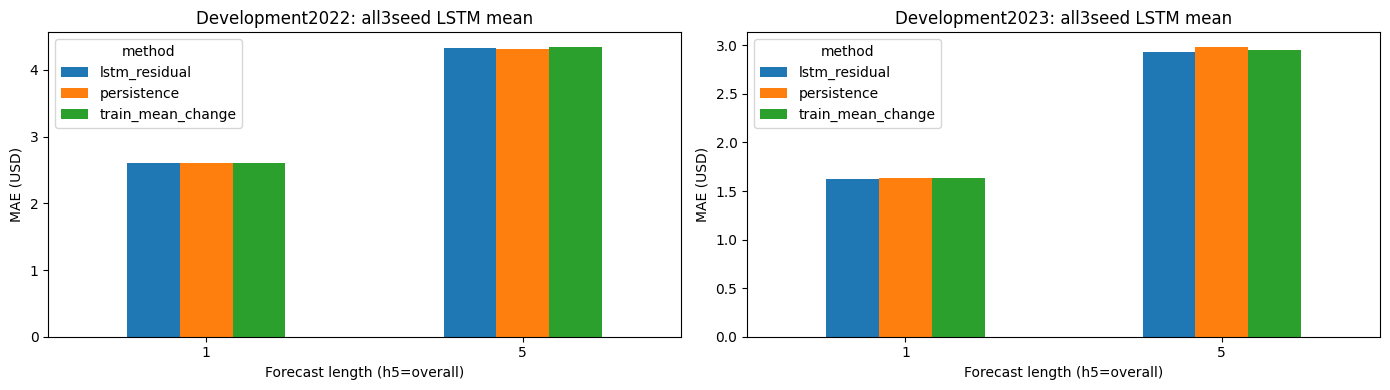

In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
learning_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
learning_pointer=json.loads((learning_root/'logs/audit/tv6_lstm_learning_latest.json').read_text())
learning_folder=(learning_root/learning_pointer['evidence']).parent
learning_receipt=json.loads((learning_folder/'summary.json').read_text())
learning_audit=json.loads((learning_folder/'independent_audit.json').read_text())
assert learning_receipt['passed'] and learning_audit['passed']
assert not learning_receipt['weight_updates'] and not learning_receipt['test_inference']
for name,sha in learning_receipt['source_hashes'].items():
    assert hashlib.sha256((learning_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in learning_audit['result_hashes'].items():
    assert hashlib.sha256((learning_folder/name).read_bytes()).hexdigest()==sha,name
learning_metrics=pd.read_csv(learning_folder/'reference_metrics.csv')
learning_primary=learning_metrics[(learning_metrics.forecast_length==1)|(learning_metrics.metric_scope=='overall')]
display(learning_primary[['validation_year','forecast_length','method','seed','samples','mae_usd','rmse_usd','bias_usd']])
learning_compare=learning_primary.groupby(['validation_year','forecast_length','method'])[['mae_usd','rmse_usd']].mean()
display(learning_compare)
display(pd.DataFrame(json.loads((learning_folder/'train_references.json').read_text())))
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,year in zip(axes,[2022,2023]):
    learning_compare.loc[year].mae_usd.unstack('method').plot.bar(ax=ax,rot=0)
    ax.set(title=f'Development{year}: all3seed LSTM mean',xlabel='Forecast length (h5=overall)',ylabel='MAE (USD)')
fig.tight_layout();fig.savefig(learning_folder/'drift_comparison.png',dpi=140);plt.show()

### Kết luận kiểm đường gradient — chưa có lỗi đứt gradient

        Zerohead làm gradient vào core bằng0 ở backward đầu tiên khi headweights còn0, nhưng gradient củahead vẫn có. Đây là hệ quả chainrule tại khởi tạo, không chứng minh core bị chặn mãi hoặc cần bỏzerohead để điểm tốt hơn.

        Tất cả checkpoint hiện có nhận coregradient hữu hạn/nonzero trên cácbatch kiểm; coreweights khác khởi tạo tái dựng theo cùngseed. Kết hợp với độ nhạy thấp ởmục6: vấn đề hiện là giá trị dự báo từ lịch sử chưa rõ, không có bằng chứng pipeline bị đứtbackprop. Không suy norm nhỏ thànhvanishinggradient: loss/thangđo/sốtham số khác nhau.

        Chưa train hoặc chỉnh learningrate/architecture. Bước nghiên cứu sửa tiếp phải làablation một yếu tố với cùngcohort/seeds/budget và log đường học, không mở thêm model. Duy trì mục tiêu LSTM và phân biệt development với kiểm chứng độc lập.

core_grad_l2  \
validation_year forecast_length state                                                     
2022            1               existing_checkpoint                            0.000995   
                                reconstructed_default_head_initialization      0.104422   
                                reconstructed_zero_head_initialization         0.000000   
                5               existing_checkpoint                            0.000786   
                                reconstructed_default_head_initialization      0.042426   
                                reconstructed_zero_head_initialization         0.000000   
2023            1               existing_checkpoint                            0.000128   
                                reconstructed_default_head_initialization      0.107683   
                                reconstructed_zero_head_initialization         0.000000   
                5               existing_checkpoint                            0.000748   
                                reconstructed_default_head_initialization      0.042657   
                                reconstructed_zero_head_initialization         0.000000   

                                                                           head_weight_grad_l2  \
validation_year forecast_length state                                                            
2022            1               existing_checkpoint                                   0.002533   
                                reconstructed_default_head_initialization             0.100993   
                                reconstructed_zero_head_initialization                0.008005   
                5               existing_checkpoint                                   0.004937   
                                reconstructed_default_head_initialization             0.039245   
                                reconstructed_zero_head_initialization                0.012852   
2023            1               existing_checkpoint                                   0.002796   
                                reconstructed_default_head_initialization             0.105155   
                                reconstructed_zero_head_initialization                0.004882   
                5               existing_checkpoint                                   0.001858   
                                reconstructed_default_head_initialization             0.038491   
                                reconstructed_zero_head_initialization                0.005470   

                                                                           head_bias_grad_l2  \
validation_year forecast_length state                                                          
2022            1               existing_checkpoint                                 0.019198   
                                reconstructed_default_head_initialization           0.229328   
                                reconstructed_zero_head_initialization              0.017934   
                5               existing_checkpoint                                 0.028293   
                                reconstructed_default_head_initialization           0.087236   
                                reconstructed_zero_head_initialization              0.028790   
2023            1               existing_checkpoint                                 0.014545   
                                reconstructed_default_head_initialization           0.237088   
                                reconstructed_zero_head_initialization              0.010938   
                5               existing_checkpoint                                 0.014530   
                                reconstructed_default_head_initialization           0.086480   
                                reconstructed_zero_head_initialization              0.012252   

                                                                           loss_sc

,validation_year,forecast_length,seed,best_epoch,core_l2_change_from_reconstructed_init,head_weight_l2,head_bias,price_scale
0,2022,1,42,1,0.743902,0.009556,[-0.00023708552475969273],39.934412
1,2022,1,123,22,3.584334,0.076580,[0.0003078969205675036],39.934412
2,2022,1,456,51,4.677340,0.106129,[0.0038307294039613524],39.934412
3,2022,5,42,1,0.507632,0.029717,"[-0.0010491674608896025, 0.0006467129711780044...",39.934412
4,2022,5,123,15,2.369046,0.110374,"[0.0023775144917229647, -0.0008718989684859102...",39.934412
5,2022,5,456,16,2.202802,0.082680,"[-0.00010740076216874448, 0.000427461070845041...",39.934412
6,2023,1,42,3,1.022350,0.013203,[0.0031328353031238347],48.587429
7,2023,1,123,4,1.326239,0.010838,[0.0036510128242089367],48.587429
8,2023,1,456,3,1.109430,0.014428,[0.0024454270360185198],48.587429
9,2023,5,42,16,3.119754,0.175067,"[0.002538642560288669, 0.00549285582631025, 0....",48.587429


min       max      mean
validation_year forecast_length                              
2022            1                0.000003  0.003457  0.000995
                5                0.000037  0.002109  0.000786
2023            1                0.000007  0.000359  0.000128
                5                0.000085  0.002702  0.000748

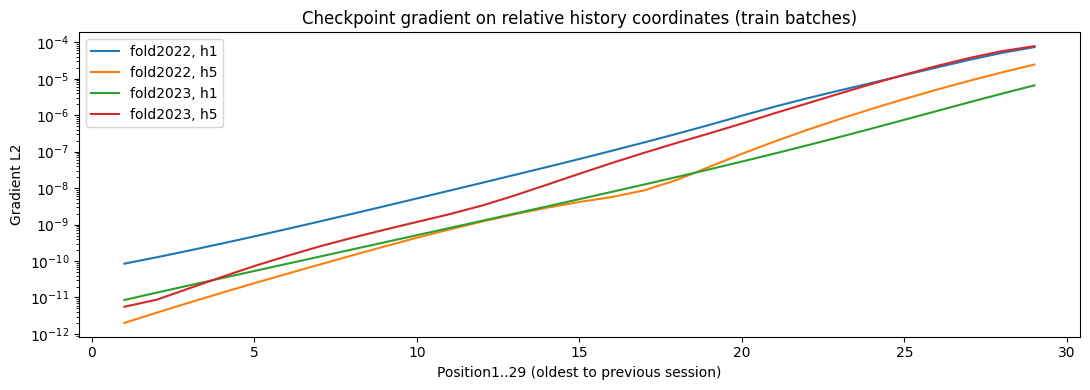

Coordinate gradient, not total raw-price sensitivity; position30 always0 after centering is excluded.
No optimizer step. Core connectivity does not establish useful predictive signal.
Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_lstm_learning_20261127T020707964054Z


In [2]:
learning_grad=pd.read_csv(learning_folder/'gradient_norms.csv')
learning_changes=pd.read_csv(learning_folder/'parameter_changes.csv')
display(learning_grad.groupby(['validation_year','forecast_length','state'])[['core_grad_l2','head_weight_grad_l2','head_bias_grad_l2','loss_scaled_mse']].mean())
display(learning_changes)
trained_grad=learning_grad[learning_grad.state=='existing_checkpoint']
assert (trained_grad.core_grad_l2>0).all()
assert (learning_changes.core_l2_change_from_reconstructed_init>0).all()
display(trained_grad.groupby(['validation_year','forecast_length']).core_grad_l2.agg(['min','max','mean']))
learning_input=pd.read_csv(learning_folder/'input_gradient_by_session.csv')
learning_input=learning_input[(learning_input.state=='existing_checkpoint')&(learning_input.session_position<30)]
fig,ax=plt.subplots(figsize=(11,4))
for (year,h),g in learning_input.groupby(['validation_year','forecast_length']):
    g.groupby('session_position').gradient_l2.mean().plot(ax=ax,label=f'fold{year}, h{h}')
ax.set(title='Checkpoint gradient on relative history coordinates (train batches)',xlabel='Position1..29 (oldest to previous session)',ylabel='Gradient L2',yscale='log')
ax.legend();fig.tight_layout();fig.savefig(learning_folder/'input_gradient.png',dpi=140);plt.show()
print('Coordinate gradient, not total raw-price sensitivity; position30 always0 after centering is excluded.')
print('No optimizer step. Core connectivity does not establish useful predictive signal.')
print('Evidence:',learning_folder)

### Ablation một yếu tố: last hidden so với mean30hidden (LSTM h1)

        Giữ4513params, cùngkhởi tạo trướczerohead, relativeinput/deltatarget/scaler/cohort/sampler/3seed/lr/batch/max100/patience10. Chỉ đổi cách đọc sequenceoutput trướcLinear.6run mean mới trêndevelopment2022/2023; lastcontrol dùngrun đãpin, khôngtrain lại hoặcchọnseed. Checkpoint mới làdevelopment, không thayv1/residualcatalog hoặctestforward.

        Chấm bằng MAE/RMSE vàreal-vsflat trêncùngmẫu. Đảo/xáo trộn làsensitivity nhân tạo, khôngchọn làm dữ liệu mới. Chỉtănggradient vềphiêncũ không đủ để giữ thayđổi. Báo đầyđủ kếtquả tốt/xấu, khôngtuning thêmgiữa chừng.

,validation_year,seed,readout,mae_usd,rmse_usd,bias_usd,std_adjustment_usd
0,2022,42,mean,2.600997,3.341541,0.161969,0.000714
4,2022,42,last,2.600649,3.341195,0.154766,0.000782
8,2022,123,mean,2.595140,3.337462,0.044038,0.007475
12,2022,123,last,2.591422,3.313741,0.332641,0.433976
16,2022,456,mean,2.599818,3.340504,0.135712,0.001183
20,2022,456,last,2.598853,3.326087,0.436431,0.479392
24,2023,42,mean,1.617497,2.105474,-0.011862,0.013600
28,2023,42,last,1.618735,2.106021,-0.008579,0.004670
32,2023,123,mean,1.617882,2.105563,-0.011947,0.010225
36,2023,123,last,1.618987,2.105912,-0.010363,0.001867


,validation_year,readout,condition,mae_mean,mae_std,rmse_mean,rmse_std
0,2022,last,flat,2.601771,0.003187,3.342360,0.002986
1,2022,last,real,2.596975,0.004892,3.327008,0.013750
2,2022,last,reverse_prefix,2.694281,0.088194,3.484827,0.135717
3,2022,last,shuffle_prefix,2.622649,0.021197,3.362310,0.025436
4,2022,mean,flat,2.598910,0.002646,3.339984,0.001866
5,2022,mean,real,2.598652,0.003098,3.339836,0.002120
6,2022,mean,reverse_prefix,2.598656,0.003083,3.339837,0.002116
7,2022,mean,shuffle_prefix,2.598653,0.003093,3.339836,0.002119
8,2023,last,flat,1.619649,0.000977,2.106067,0.000432
9,2023,last,real,1.619409,0.000959,2.106283,0.000550


condition                         flat      real  reverse_prefix  \
validation_year seed readout                                       
2022            42   last     2.600688  2.600649        2.600491   
                     mean     2.601055  2.600997        2.600993   
                123  last     2.599267  2.591422        2.706814   
                     mean     2.595953  2.595140        2.595162   
                456  last     2.605359  2.598853        2.775538   
                     mean     2.599721  2.599818        2.599812   
2023            42   last     1.619055  1.618735        1.616874   
                     mean     1.618993  1.617497        1.617529   
                123  last     1.619115  1.618987        1.618211   
                     mean     1.619042  1.617882        1.617906   
                456  last     1.620776  1.620507        1.617724   
                     mean     1.620734  1.618608        1.618663   

condition                     shuffle_prefix  flat_minus_real  
validation_year seed readout                                   
2022            42   last           2.600587         0.000038  
                     mean           2.600996         0.000058  
                123  last           2.624501         0.007845  
                     mean           2.595148         0.000813  
                456  last           2.642859         0.006506  
                     mean           2.599816        -0.000098  
2023            42   last           1.617712         0.000321  
                     mean           1.617513         0.001496  
                123  last           1.618547         0.000127  
                     mean           1.617898         0.001159  
                456  last           1.619204         0.000269  
                     mean           1.618638         0.002126

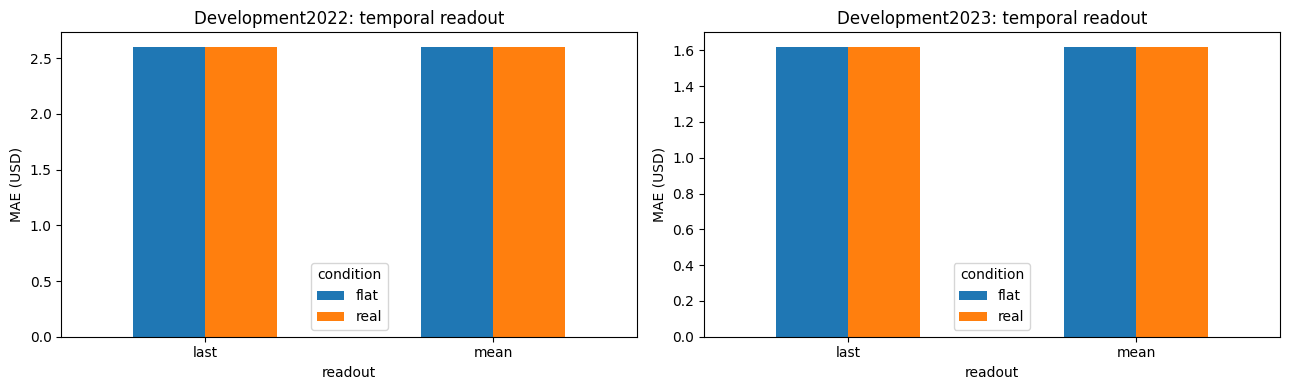

No independent held-out claim; evaluate both folds and MAE/RMSE, not a single best seed.


In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
readout_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
readout_pointer=json.loads((readout_root/'logs/audit/tv6_readout_ablation_latest.json').read_text())
readout_folder=(readout_root/readout_pointer['evidence']).parent
readout_receipt=json.loads((readout_folder/'summary.json').read_text())
readout_audit=json.loads((readout_folder/'independent_audit.json').read_text())
assert readout_receipt['passed'] and readout_audit['passed']
assert len(readout_receipt['runs'])==6 and not readout_receipt['test_forward'] and not readout_receipt['promoted']
for name,sha in readout_receipt['source_hashes'].items():
    assert hashlib.sha256((readout_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in readout_audit['result_hashes'].items():
    assert hashlib.sha256((readout_folder/name).read_bytes()).hexdigest()==sha,name
readout_metrics=pd.read_csv(readout_folder/'metrics.csv')
display(readout_metrics[readout_metrics.condition=='real'][['validation_year','seed','readout','mae_usd','rmse_usd','bias_usd','std_adjustment_usd']])
readout_aggregate=readout_metrics.groupby(['validation_year','readout','condition']).agg(mae_mean=('mae_usd','mean'),mae_std=('mae_usd','std'),rmse_mean=('rmse_usd','mean'),rmse_std=('rmse_usd','std')).reset_index()
display(readout_aggregate)
readout_sensitivity=readout_metrics.pivot(index=['validation_year','seed','readout'],columns='condition',values='mae_usd')
readout_sensitivity['flat_minus_real']=readout_sensitivity['flat']-readout_sensitivity['real']
display(readout_sensitivity)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,year in zip(axes,[2022,2023]):
    readout_metrics[(readout_metrics.validation_year==year)&readout_metrics.condition.isin(['real','flat'])].groupby(['readout','condition']).mae_usd.mean().unstack('condition').plot.bar(ax=ax,rot=0)
    ax.set(title=f'Development{year}: temporal readout',ylabel='MAE (USD)')
fig.tight_layout();fig.savefig(readout_folder/'readout_comparison.png',dpi=140);plt.show()
print('No independent held-out claim; evaluate both folds and MAE/RMSE, not a single best seed.')

### Loghuấn luyện vàgradient củaablation

        Loggradient được đo trêncopy của trạngthái tại cácepoch cốđịnh bằng cùngbatchtrainmiddle32; không thêmoptimizerstep, khôngsửa RNG/modelgốc. Đây làthước đođường học, không làtiêu chí thayMAE/RMSE. Các đườngloss làrunthật, checkpointbest được reload vàđốichiếu.

        Chỉ đưa meanreadout vào ứngviên nếu cóbằngchứng tốt hơn nhấtquán; nếu không thìgiữ lastreadout. Không thửthêm hyperparameter trong lầnablation này hoặc thaymôhình demo tựđộng.

,validation_year,seed,best_epoch,epochs,checkpoint
0,2022,42,1,11,artifacts/checkpoints/tv6_readout_ablation_202...
1,2022,123,3,13,artifacts/checkpoints/tv6_readout_ablation_202...
2,2022,456,5,15,artifacts/checkpoints/tv6_readout_ablation_202...
3,2023,42,3,13,artifacts/checkpoints/tv6_readout_ablation_202...
4,2023,123,4,14,artifacts/checkpoints/tv6_readout_ablation_202...
5,2023,456,3,13,artifacts/checkpoints/tv6_readout_ablation_202...


,validation_year,seed,epoch,loss_scaled_mse,core_grad_l2,oldest_input_grad,previous_input_grad
0,2022,42,1,0.000297,0.000049,1.809449e-08,2.230900e-08
1,2022,42,5,0.000272,0.000011,1.263588e-07,1.040457e-07
2,2022,42,10,0.000294,0.000020,7.478915e-08,6.352529e-08
3,2022,123,1,0.000279,0.000022,1.211690e-07,8.955502e-08
4,2022,123,5,0.000276,0.000029,1.999993e-07,1.564484e-07
5,2022,123,10,0.000303,0.000027,5.635214e-08,4.836632e-08
6,2022,456,1,0.000280,0.000035,2.323922e-07,1.767893e-07
7,2022,456,5,0.000305,0.000092,2.964271e-08,1.895342e-08
8,2022,456,10,0.000267,0.000023,1.725265e-07,1.593375e-07
9,2023,42,1,0.000217,0.000104,3.556666e-07,2.823228e-07


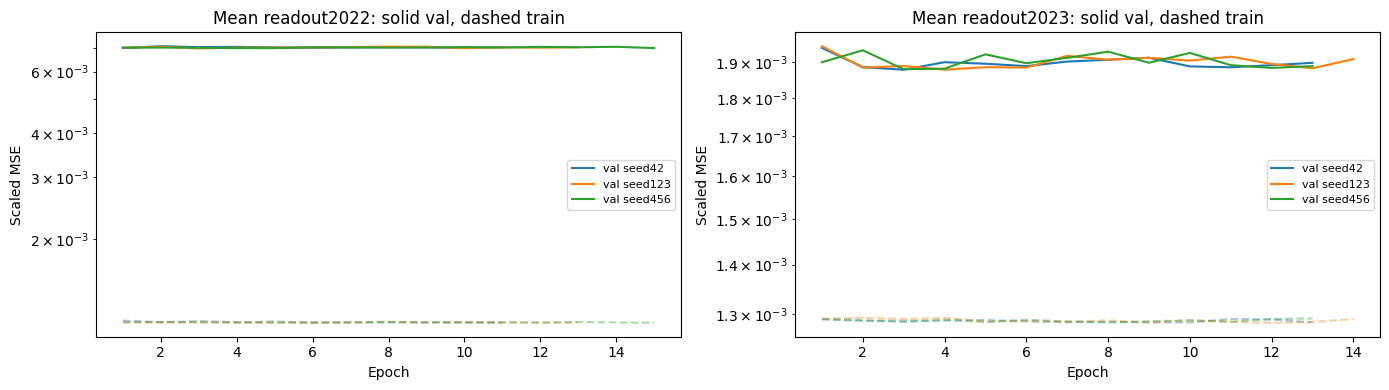

Detailed decision/report: reports/audits/TV6_Readout_Ablation.md
Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_readout_ablation_20261127T021734341342Z


In [2]:
display(pd.DataFrame(readout_receipt['runs']))
readout_gradient=pd.read_csv(readout_folder/'gradient_log.csv')
display(readout_gradient[['validation_year','seed','epoch','loss_scaled_mse','core_grad_l2','oldest_input_grad','previous_input_grad']])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,year in zip(axes,[2022,2023]):
    for seed in [42,123,456]:
        history=pd.read_csv(readout_folder/f'{year}_mean_readout_seed{seed}'/'epoch_logs.csv')
        line=ax.plot(history.epoch,history.val_loss,label=f'val seed{seed}')[0]
        ax.plot(history.epoch,history.train_loss,'--',color=line.get_color(),alpha=.4)
    ax.set(title=f'Mean readout{year}: solid val, dashed train',xlabel='Epoch',ylabel='Scaled MSE',yscale='log')
    ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(readout_folder/'readout_training.png',dpi=140);plt.show()
print('Detailed decision/report: reports/audits/TV6_Readout_Ablation.md')
print('Evidence:',readout_folder)

### Hoàn thành hạng mục: chốt ứng viên và kiểm chứng đường dự báo

        Theo yêu cầu không train thêm: giữ LSTM residual last, một/năm bước, ba seed42/123/456. Khóa sáu checkpoint/scaler/representation trongconfig tv6_lstm_residual_candidate_v1.json trước testforward. Không tạo kiến trúc/weights mới, không chọnseed theo test, không đổi catalogv1.

        Kiểm lại12validationpipelines của2fold và6testpipelines: rawinput→relativehistory→checkpoint→delta→origin+scale×delta→USD. Scalerfit/partialfit bị chặn, model eval/no-grad, hash/state trước/sau khớp, batchcuối vàbatch1 khớp; actual được ghép sauforward. H5 không cộng dồn recursive hoặc dùnginverse absolute-price nhầm cho delta.

        Protocol riêng ghi rõ test2024–2025 đã được quan sát trước cải tiến: kết quả dưới là **post-development evaluation, không độc lập**. Không tuning sau kết quả. Giữ riêng kết quả v1 đã công bố, không thay bằng điểm development/residual. Hạng mục audit/chốt ứng viên hoàn thành; chưa tự triển khai release/API/demo của mục7–9.

,forecast_length,seed,checkpoint,scaler_id,best_epoch,readout
0,1,42,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,3,last
1,1,123,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,4,last
2,1,456,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,3,last
3,5,42,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,16,last
4,5,123,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,7,last
5,5,456,artifacts/checkpoints/tv6_residual_development...,tv6_dev_prices_to_2022_20261127T012509759710Z,3,last


,candidate_models,pipeline_checks,training_performed,refit_performed,weights_changed,independent_holdout,test_label
0,6,18,False,False,False,False,post-development evaluation on previously obse...


,model,phase,forecast_length,seeds,mae_usd,rmse_usd,sample_count
0,LSTM residual last,development_2022,1,3,2.596975,3.327008,251
1,LSTM residual last,development_2022,5,3,4.323299,5.510879,247
2,Persistence,development_2022,1,0,2.602120,3.342642,251
3,Persistence,development_2022,5,0,4.313107,5.499468,247
4,LSTM residual last,development_2023,1,3,1.619409,2.106283,250
5,LSTM residual last,development_2023,5,3,2.931102,3.841833,246
6,Persistence,development_2023,1,0,1.636779,2.120593,250
7,Persistence,development_2023,5,0,2.984996,3.903600,246
8,LSTM residual last,post_development_test_2024_2025,1,3,2.465892,3.652078,502
9,LSTM residual last,post_development_test_2024_2025,5,3,4.607636,6.682840,498


,scope,forecast_length,method,seed,horizon_step,metric_scope,sample_count,error_count,mae_usd,rmse_usd
56,post_development_test_2024_2025,1,persistence,NaN,1.0,per_horizon,502,502,2.476989,3.654583
57,post_development_test_2024_2025,1,lstm_residual,42.0,1.0,per_horizon,502,502,2.465605,3.652406
58,post_development_test_2024_2025,1,lstm_residual,123.0,1.0,per_horizon,502,502,2.465336,3.652103
59,post_development_test_2024_2025,1,lstm_residual,456.0,1.0,per_horizon,502,502,2.466734,3.651726
60,post_development_test_2024_2025,5,persistence,NaN,1.0,per_horizon,498,498,2.491542,3.668619
61,post_development_test_2024_2025,5,persistence,NaN,2.0,per_horizon,498,498,3.763667,5.379357
62,post_development_test_2024_2025,5,persistence,NaN,3.0,per_horizon,498,498,4.793967,6.795413
63,post_development_test_2024_2025,5,persistence,NaN,4.0,per_horizon,498,498,5.654790,7.830747
64,post_development_test_2024_2025,5,persistence,NaN,5.0,per_horizon,498,498,6.458521,8.662624
65,post_development_test_2024_2025,5,persistence,NaN,NaN,overall,498,2490,4.632497,6.707243


,scope,forecast_length,horizon_step,metric_scope,mae_mean,mae_std,rmse_mean,rmse_std,seeds
14,post_development_test_2024_2025,1,1.0,per_horizon,2.465892,0.000741,3.652078,0.000340,3
15,post_development_test_2024_2025,5,1.0,per_horizon,2.488513,0.005504,3.669600,0.002438,3
16,post_development_test_2024_2025,5,2.0,per_horizon,3.747791,0.001564,5.370526,0.000279,3
17,post_development_test_2024_2025,5,3.0,per_horizon,4.763892,0.001774,6.770021,0.009658,3
18,post_development_test_2024_2025,5,4.0,per_horizon,5.614288,0.007290,7.797586,0.012071,3
19,post_development_test_2024_2025,5,5.0,per_horizon,6.423698,0.003231,8.623088,0.005346,3
20,post_development_test_2024_2025,5,NaN,overall,4.607636,0.001169,6.682840,0.005690,3


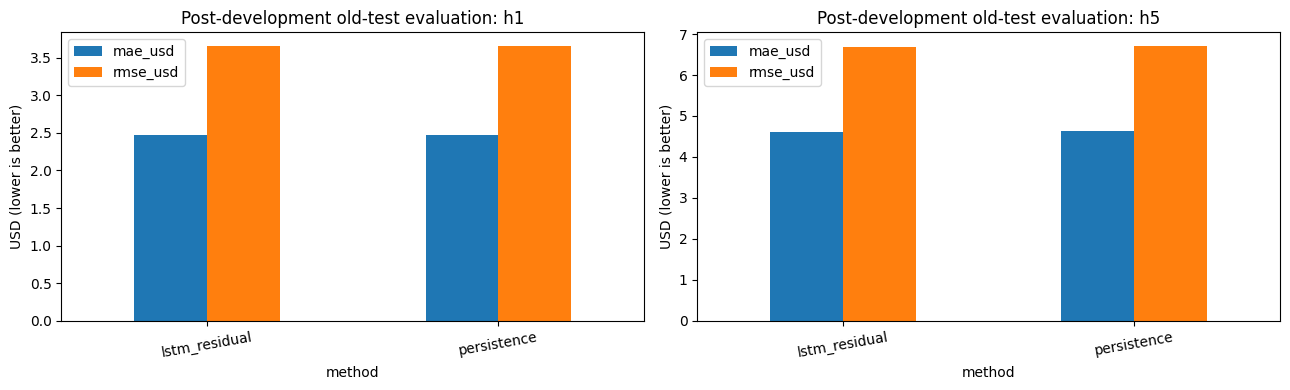

Research candidate only. Old test has informed development; not independent held-out proof.


In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
completion_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
completion_pointer=json.loads((completion_root/'logs/audit/tv6_lstm_completion_latest.json').read_text())
completion_folder=(completion_root/completion_pointer['evidence']).parent
completion_receipt=json.loads((completion_folder/'summary.json').read_text())
completion_audit=json.loads((completion_folder/'independent_audit.json').read_text())
assert completion_receipt['passed'] and completion_audit['passed']
assert not completion_receipt['training_performed'] and not completion_receipt['refit_performed']
assert not completion_receipt['weights_changed'] and not completion_receipt['independent_holdout']
for name,sha in completion_receipt['source_hashes'].items():
    assert hashlib.sha256((completion_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in completion_audit['result_hashes'].items():
    assert hashlib.sha256((completion_folder/name).read_bytes()).hexdigest()==sha,name
for name,sha in completion_audit['comparison_source_hashes'].items():
    assert hashlib.sha256((completion_root/name).read_bytes()).hexdigest()==sha,name
candidate_config=json.loads((completion_root/completion_receipt['candidate_config']).read_text())
display(pd.DataFrame(candidate_config['semantic']['models']))
display(pd.DataFrame([{k:completion_receipt[k] for k in ['candidate_models','pipeline_checks','training_performed','refit_performed','weights_changed','independent_holdout','test_label']}]))
completion_comparison=pd.read_csv(completion_folder/'comparison.csv')
display(completion_comparison)
completion_metrics=pd.read_csv(completion_folder/'metrics.csv')
completion_aggregates=pd.read_csv(completion_folder/'aggregates.csv')
post_metrics=completion_metrics[completion_metrics.scope=='post_development_test_2024_2025']
display(post_metrics)
display(completion_aggregates[completion_aggregates.scope=='post_development_test_2024_2025'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,h in zip(axes,[1,5]):
    p=post_metrics[(post_metrics.forecast_length==h)&((post_metrics.forecast_length==1)|(post_metrics.metric_scope=='overall'))]
    p.groupby('method')[['mae_usd','rmse_usd']].mean().plot.bar(ax=ax,rot=10)
    ax.set(title=f'Post-development old-test evaluation: h{h}',ylabel='USD (lower is better)')
fig.tight_layout();fig.savefig(completion_folder/'candidate_evaluation.png',dpi=140);plt.show()
print('Research candidate only. Old test has informed development; not independent held-out proof.')

### Nghiệm thu phạm vi và các giới hạn còn lại

        Đã có bảng tổng hợp theo phase, registry sáu ứng viên, protocol riêng trước đánh giá, số liệu đủba seed/horizon và audit độc lập. Không bổ sung train/model trong bước chốt. Meanreadout không được chọn; weights/checkpoint cũ không ghi đè.

        Trên đánh giá sau phát triển testcũ, residual h1MAE2,465892/RMSE3,652078USD so persistence2,476989/3,654583; h5overall4,607636/6,682840 so4,632497/6,707243. Lợi thế nhỏ, chưa có significance/thực tiễn hoặc bằng chứng độc lập. Lịch sử thật đóng góp chưa rõ theo probes trước; không tuyên bố đã tìm ra quy luật giá hoặc lợi nhuận giao dịch.

        Kết luận: hoàn thành hạng mục kiểm chứng và chốt candidate trong giới hạn không train thêm; chưa chứng minh LSTM vượt baseline bền vững và chưa là release tích hợp. Các bước7–10 tiếp tục khi người dùng giao, không tự sửa catalog hoặc tiếp tục tuning theo bảng này.

,scope,forecast_length,seed,input_samples,checkpoint,batch_tail,boundary_single_sample_matches,source_validation_predictions_match,dtype,no_grad,weights_unchanged
0,development_2022,1,42,251,artifacts/checkpoints/tv6_residual_development...,27,True,True,float64,True,True
1,development_2022,1,123,251,artifacts/checkpoints/tv6_residual_development...,27,True,True,float64,True,True
2,development_2022,1,456,251,artifacts/checkpoints/tv6_residual_development...,27,True,True,float64,True,True
3,development_2022,5,42,247,artifacts/checkpoints/tv6_residual_development...,23,True,True,float64,True,True
4,development_2022,5,123,247,artifacts/checkpoints/tv6_residual_development...,23,True,True,float64,True,True
5,development_2022,5,456,247,artifacts/checkpoints/tv6_residual_development...,23,True,True,float64,True,True
6,development_2023,1,42,250,artifacts/checkpoints/tv6_residual_development...,26,True,True,float64,True,True
7,development_2023,1,123,250,artifacts/checkpoints/tv6_residual_development...,26,True,True,float64,True,True
8,development_2023,1,456,250,artifacts/checkpoints/tv6_residual_development...,26,True,True,float64,True,True
9,development_2023,5,42,246,artifacts/checkpoints/tv6_residual_development...,22,True,True,float64,True,True


,passed,candidate_models,pipeline_checks,metric_rows_verified,aggregate_rows_verified,prediction_rows_verified,source_and_weight_hashes_unchanged,independent_holdout
0,True,6,18,84,21,23832,True,False


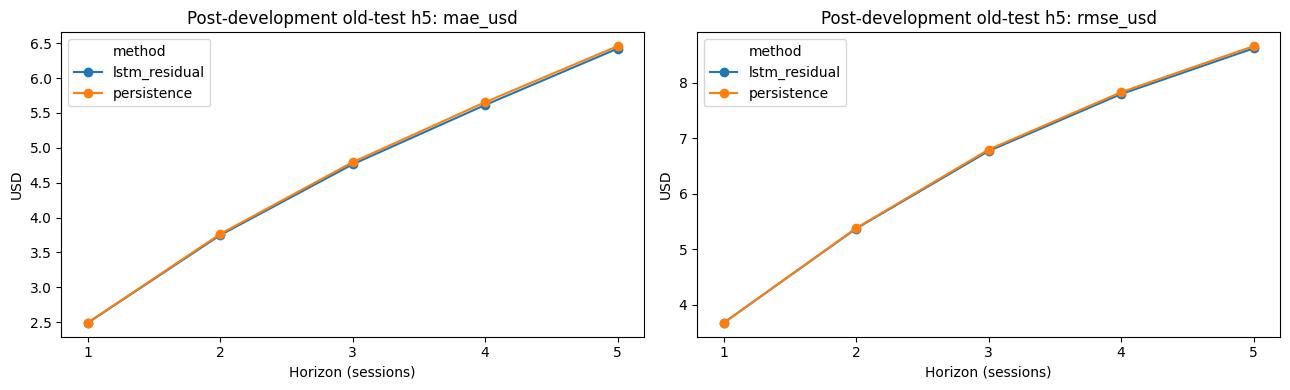

Candidate config: experiments/configs/tv6_lstm_residual_candidate_v1.json
Conclusion: item completed; no further training or automatic promotion.
Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_lstm_completion_20261127T023617456097Z


In [2]:
display(pd.read_csv(completion_folder/'pipeline_checks.csv'))
display(pd.DataFrame([{k:v for k,v in completion_audit.items() if k not in ['result_hashes','comparison_source_hashes']}]))
post_h5=post_metrics[(post_metrics.forecast_length==5)&(post_metrics.metric_scope=='per_horizon')]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['mae_usd','rmse_usd']):
    post_h5.groupby(['horizon_step','method'])[metric].mean().unstack('method').plot(ax=ax,marker='o')
    ax.set(title=f'Post-development old-test h5: {metric}',xlabel='Horizon (sessions)',ylabel='USD',xticks=[1,2,3,4,5])
fig.tight_layout();fig.savefig(completion_folder/'candidate_horizons.png',dpi=140);plt.show()
print('Candidate config:',completion_receipt['candidate_config'])
print('Conclusion: item completed; no further training or automatic promotion.')
print('Evidence:',completion_folder)

## 7. Đóng gói release và tích hợp inference

        Release `aapl-research-residual-v1`: sáu LSTM residual last (h1/h5 × ba seed), ba CNN h1 gốc và persistence. Manifest/registry liên kết chính xác weights, scaler, snapshot và sourcehash. Không thay trọng số, train, tuning hoặc source/catalogv1. Default demo seed42 cố định trước, không chọn theo test.

        Inference chỉ nhận bảy trường Forecast Input. Rawhistory→kiểm snapshot/contract→encoder theo model→CPU64model→decoder đúng→predictions USD. LSTM decode origin+scale×delta; CNN inverse absolute scaling; h5 trực tiếp năm output, không recursive. Không có actual/error trong response inference.

        Lịch sử2023–2025, mọi target h5 cùngsplit; không live hoặc ngày tương lai ngoài snapshot. API/frontend còn mục8/9. Source ZIP cục bộ nạp được sau giải nén trong tiến trình Python riêng; không đồng nghĩa đã chạy máy thành viên khác. Giới hạn test sau phát triển và lợi thế baseline nhỏ được giữ trongmanifest/output.

,method,forecast_length,seed,scaler_id,representation,readout,best_epoch
0,lstm,1,42,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,3
1,lstm,1,123,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,4
2,lstm,1,456,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,3
3,lstm,5,42,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,16
4,lstm,5,123,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,7
5,lstm,5,456,tv6_dev_prices_to_2022_20261127T012509759710Z,origin-centered-price-delta-v1,last,3
6,cnn,1,42,aapl_scaler_20261120T124720810874Z,absolute-standardscaled-price-v1,cnn,32
7,cnn,1,123,aapl_scaler_20261120T124720810874Z,absolute-standardscaled-price-v1,cnn,41
8,cnn,1,456,aapl_scaler_20261120T124720810874Z,absolute-standardscaled-price-v1,cnn,43


,release_id,kind,dataset_version,lookback,dtype,demo_seed,independent_holdout,limitations
0,aapl-research-residual-v1,historical-research,aapl_2015_2025_acq_20261119T141302002415Z,30,float64,42,False,"[Historical adjusted AAPL prices, retrospectiv..."


,release_id,method,seed,forecast_origin,forecast_length,horizon_step,target_date,predicted_price,currency,scope
0,aapl-research-residual-v1,lstm,42.0,2023-06-15,1,1,2023-06-16,183.378508,USD,historical_validation
1,aapl-research-residual-v1,cnn,42.0,2023-06-15,1,1,2023-06-16,179.957479,USD,historical_validation
2,aapl-research-residual-v1,persistence,NaN,2023-06-15,1,1,2023-06-16,183.141083,USD,historical_validation
3,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,1,2023-06-16,183.233722,USD,historical_validation
4,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,2,2023-06-20,183.376884,USD,historical_validation
5,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,3,2023-06-21,183.350910,USD,historical_validation
6,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,4,2023-06-22,183.547834,USD,historical_validation
7,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,5,2023-06-23,183.587612,USD,historical_validation
8,aapl-research-residual-v1,persistence,NaN,2023-06-15,5,1,2023-06-16,183.141083,USD,historical_validation
9,aapl-research-residual-v1,persistence,NaN,2023-06-15,5,2,2023-06-20,183.141083,USD,historical_validation


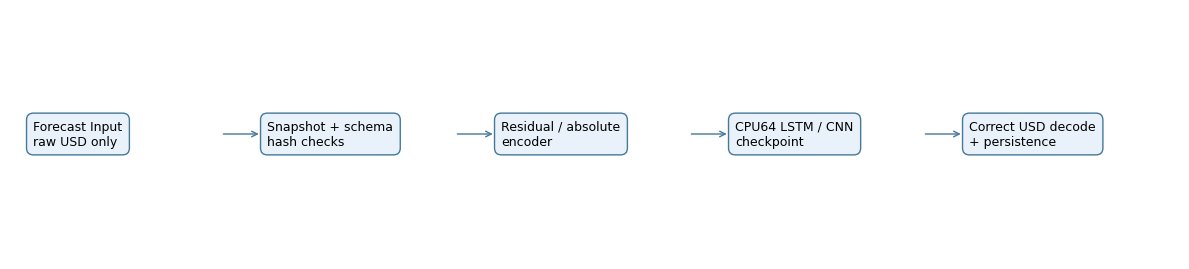

Actual backend inference on validation date, no metric/training. No API endpoint yet.


In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
release_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
sys.path.insert(0,str(release_root))
from backend.artifacts.research_release import validate_release
from backend.inference.release_forecaster import ReleaseForecaster
release_document=validate_release(release_root)
release_semantic=release_document['semantic']
release_engine=ReleaseForecaster(release_root)
display(pd.DataFrame(release_semantic['models'])[['method','forecast_length','seed','scaler_id','representation','readout','best_epoch']])
display(pd.DataFrame([release_engine.metadata]))
release_frame=pd.read_csv(release_root/release_semantic['snapshot'],float_precision='round_trip')
release_days=release_frame.date.tolist();origin='2023-06-15';i=release_days.index(origin)
release_demo=[]
for h in [1,5]:
    record=dict(sample_id=f'{release_semantic["dataset_version"]}:lb30:f{h}:{origin}',dataset_version=release_semantic['dataset_version'],
        forecast_origin=origin,input_dates=release_days[i-29:i+1],input_values=[[v] for v in release_frame.adjusted_close.iloc[i-29:i+1]],lookback=30,forecast_length=h)
    release_demo.extend(release_engine.predict([record],methods=['lstm','cnn','persistence'] if h==1 else ['lstm','persistence']))
display(pd.DataFrame(release_demo)[['release_id','method','seed','forecast_origin','forecast_length','horizon_step','target_date','predicted_price','currency','scope']])
fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
labels=['Forecast Input\nraw USD only','Snapshot + schema\nhash checks','Residual / absolute\nencoder','CPU64 LSTM / CNN\ncheckpoint','Correct USD decode\n+ persistence']
for j,label in enumerate(labels):
    x=.02+j*.20
    ax.text(x,.5,label,ha='left',va='center',fontsize=9,bbox=dict(boxstyle='round,pad=.55',facecolor='#e9f2fa',edgecolor='#46789a'),transform=ax.transAxes)
    if j<4:ax.annotate('',xy=(x+.195,.5),xytext=(x+.16,.5),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#46789a'))
fig.tight_layout();plt.show()
print('Actual backend inference on validation date, no metric/training. No API endpoint yet.')

### Nghiệm thu end-to-end và gói release

        14tests tích hợp trên bản chính thức đạt: positiveh1/h5/repeat/no-fit, input cótarget/giá-ngày-version sai/duplicate, seed sai, CNNh5/crosssplit, artifacthash và sai scalerkể cảmanifest được reseal trongfixture. Toàn bộ22nhóm method/mode/seed/split với20.144predictions validation/test khớp bằng0 với evidence được nghiệm thu.

        ZIP chứa manifest/registry, chíncheckpoint, scaler đúng bộ, snapshot, backend source, dependencylock vàverifier. Không là toàn bộ gói log nghiên cứu. Nạp từ nguồn giải nén riêng bằngPython isolatedmode(-I), kiểm đủ9model/3seed, outputdigest khớp workspace. Cùngmáy/cùngdependencyenv, chưa chứng nhận máy khác.

        Mục7 hoàn thành local: đủ bộnạp/inference để nối API ởmục8. Không tự tạoAPI/giao diện, không upload hoặc push. Các metric sau phát triển không được đổi thành independentholdout hoặc lợi nhuận giao dịch.

In [2]:
release_pointer=json.loads((release_root/'logs/audit/tv6_item7_latest.json').read_text())
release_evidence=(release_root/release_pointer['evidence']).parent
release_acceptance=json.loads((release_evidence/'acceptance.json').read_text())
assert release_acceptance['passed'] and release_acceptance['integration_tests_passed']==14
for name,sha in release_acceptance['evidence_hashes'].items():
    assert hashlib.sha256((release_evidence/name).read_bytes()).hexdigest()==sha,name
assert hashlib.sha256((release_root/release_acceptance['zip_path']).read_bytes()).hexdigest()==release_acceptance['zip_sha256']
assert hashlib.sha256((release_root/release_acceptance['portability_evidence']).read_bytes()).hexdigest()==release_acceptance['portability_evidence_sha256']
display(pd.DataFrame([{k:v for k,v in release_acceptance.items() if k!='evidence_hashes'}]))
display(pd.read_csv(release_evidence/'checks.csv'))
release_portability=json.loads((release_root/release_acceptance['portability_evidence']).read_text())
assert release_portability['workspace']['prediction_sha256']==release_portability['extracted']['prediction_sha256']
print('ZIP:',release_root/release_acceptance['zip_path'])
print('Manifest:',release_root/'artifacts/releases/aapl-research-residual-v1/manifest.json')
print('Isolated source root:',release_portability['extracted']['source_root'])
print('Next: mục8 API, no further training required.')

,passed,release_id,release_sha256,integration_tests_passed,method_mode_checks,prediction_rows_verified,exact_prediction_parity,portable_source_isolation_verified,portability_evidence,portability_evidence_sha256,tests_evidence,tests_evidence_sha256,zip_path,zip_sha256,zip_bytes,training,api_implemented,frontend_implemented,verified_on_other_machine
0,True,aapl-research-residual-v1,a4b04a50c3e499b95407a5a8f9de379a40f6371bbb532c...,14,22,20144,True,True,logs/audit/tv6_release_portability_20261127T03...,5ac1b9b6885b100f1096da516cb3a3ccc41d95ec5a2d38...,logs/audit/tv6_item7_release_final_tests.xml,8d1bed71bed437e13778d4b0dd85d1368f9293bf981c93...,artifacts/releases/aapl-research-residual-v1.zip,3597bf6c98a5620a0c9c0ecd033a1f52a8c4e29aa6d78f...,791355,False,False,False,False


,split,forecast_length,seed,method,samples,prediction_rows,tail_samples,max_abs_difference,request_seconds
0,val,1,42.0,lstm,250,250,26,0.0,0.837622
1,val,1,42.0,cnn,250,250,26,0.0,0.837622
2,val,1,NaN,persistence,250,250,26,0.0,0.837622
3,val,1,123.0,lstm,250,250,26,0.0,0.788551
4,val,1,123.0,cnn,250,250,26,0.0,0.788551
5,val,1,456.0,lstm,250,250,26,0.0,0.815619
6,val,1,456.0,cnn,250,250,26,0.0,0.815619
7,val,5,42.0,lstm,246,1230,22,0.0,0.783819
8,val,5,NaN,persistence,246,1230,22,0.0,0.783819
9,val,5,123.0,lstm,246,1230,22,0.0,0.867924


ZIP: D:\learn_DeepLearning\Project_course-work\artifacts\releases\aapl-research-residual-v1.zip
Manifest: D:\learn_DeepLearning\Project_course-work\artifacts\releases\aapl-research-residual-v1\manifest.json
Isolated source root: D:\learn_DeepLearning\Project_course-work\.venv\tv6_release_verify_20261127T031224457203Z
Next: mục8 API, no further training required.


## 8. API lịch sử theo release — FastAPI/Uvicorn

        API prefix/api/v1, không train hoặc downloadlive. Dùngrelease aapl-research-residual-v1 của mục7, giữ nguyênsource/weights/scaler đãpin. Backend mới chỉ điều phối input theoorigin, inference, đọcresultssidecar vàmetricEvaluation; khôngviết lại côngthức model.

        Endpoint: health/readiness; releasecurrent/detail; forecastorigins; datasetprices; predictions; storedresults/metrics; experiments/history/audits; verifiedLSTMtrace. Health độc lập artifact; readiness kiểm đủ9model vàresults. Client khôngtruyềntarget/scaler/checkpointpath. Seed42default,42/123/456được hỗtrợ. H5 khôngCNN hoặccrosssplit.

        RequestID vàHTTP404/422/503/500 theo contract, traceback/path nội bộ chỉ tronglog. List/ranges có giới hạn/phântrang. Kết quảinference khôngchứaactual; comparison đượcghép sau. Results/metrics đọc dữ liệuđãlưu, táchevaluationphase, không tạo tuyênbốtestđộclập. Frontend cònmục9.

D:\learn_DeepLearning\Project_course-work\.venv\tv4_clean\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


,request_id,status,release_id,release_sha256,models_verified,results_verified
0,903b98e5381946bf8664a0b88d6bd60c,ready,aapl-research-residual-v1,a4b04a50c3e499b95407a5a8f9de379a40f6371bbb532c...,9,True


,release_id,method,seed,forecast_origin,horizon_step,target_date,predicted_price,currency
0,aapl-research-residual-v1,lstm,42.0,2023-06-15,1,2023-06-16,183.233722,USD
1,aapl-research-residual-v1,lstm,42.0,2023-06-15,2,2023-06-20,183.376884,USD
2,aapl-research-residual-v1,lstm,42.0,2023-06-15,3,2023-06-21,183.350910,USD
3,aapl-research-residual-v1,lstm,42.0,2023-06-15,4,2023-06-22,183.547834,USD
4,aapl-research-residual-v1,lstm,42.0,2023-06-15,5,2023-06-23,183.587612,USD
5,aapl-research-residual-v1,persistence,NaN,2023-06-15,1,2023-06-16,183.141083,USD
6,aapl-research-residual-v1,persistence,NaN,2023-06-15,2,2023-06-20,183.141083,USD
7,aapl-research-residual-v1,persistence,NaN,2023-06-15,3,2023-06-21,183.141083,USD
8,aapl-research-residual-v1,persistence,NaN,2023-06-15,4,2023-06-22,183.141083,USD
9,aapl-research-residual-v1,persistence,NaN,2023-06-15,5,2023-06-23,183.141083,USD


,method,seed,forecast_length,horizon_step,metric_scope,sample_count,error_count,mae_usd,rmse_usd,currency,range_kind,evaluation_phase,independent_holdout
0,lstm,42.0,5,1.0,per_horizon,11,11,1.251482,1.476302,USD,selected_range,validation_used_for_selection,False
1,lstm,42.0,5,2.0,per_horizon,11,11,1.593928,1.820808,USD,selected_range,validation_used_for_selection,False
2,lstm,42.0,5,3.0,per_horizon,11,11,2.107854,2.488025,USD,selected_range,validation_used_for_selection,False
3,lstm,42.0,5,4.0,per_horizon,11,11,2.141541,2.689966,USD,selected_range,validation_used_for_selection,False
4,lstm,42.0,5,5.0,per_horizon,11,11,2.300151,3.017582,USD,selected_range,validation_used_for_selection,False
5,lstm,42.0,5,NaN,overall,11,55,1.878991,2.367564,USD,selected_range,validation_used_for_selection,False
6,persistence,NaN,5,1.0,per_horizon,11,11,1.273675,1.527624,USD,selected_range,validation_used_for_selection,False
7,persistence,NaN,5,2.0,per_horizon,11,11,1.692574,1.952107,USD,selected_range,validation_used_for_selection,False
8,persistence,NaN,5,3.0,per_horizon,11,11,2.272579,2.647707,USD,selected_range,validation_used_for_selection,False
9,persistence,NaN,5,4.0,per_horizon,11,11,2.359403,2.974420,USD,selected_range,validation_used_for_selection,False


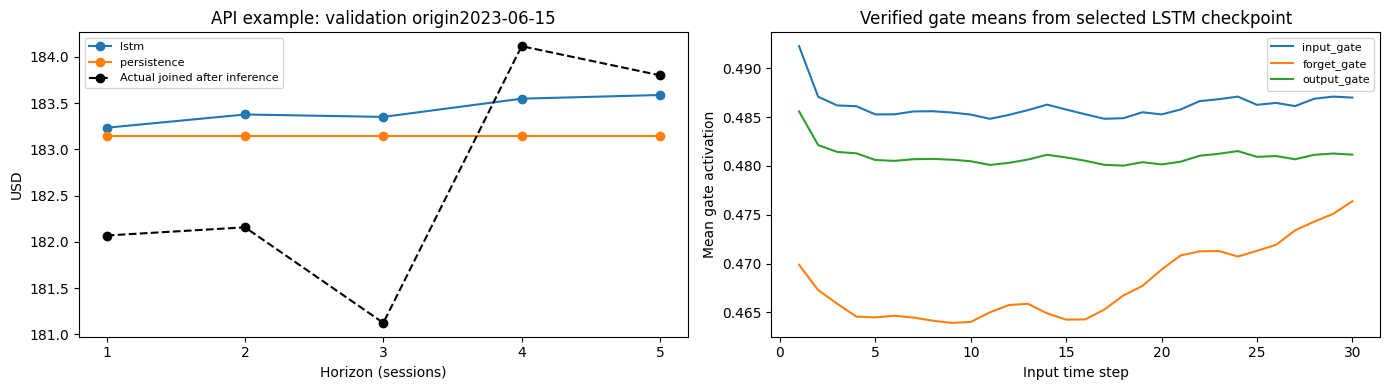

Example selected date, not aggregate performance evidence. API does not improve weights.
Trace verified: {'passed': True, 'rtol': 1e-10, 'atol': 1e-12, 'max_hidden_abs_error': 2.7755575615628914e-17, 'max_cell_abs_error': 6.938893903907228e-18, 'max_prediction_abs_error': 0.0}


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
api_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'rule.md').is_file())
sys.path.insert(0,str(api_root))
from fastapi.testclient import TestClient
from backend.api.app import create_app
with TestClient(create_app(api_root)) as api_client:
    api_health=api_client.get('/api/v1/health').json()
    api_ready=api_client.get('/api/v1/readiness').json()
    api_meta=api_client.get('/api/v1/releases/current').json()
    api_pred_response=api_client.post('/api/v1/predictions',json={'forecast_origin':'2023-06-15','forecast_length':5})
    assert api_pred_response.status_code==200,api_pred_response.text
    api_pred=api_pred_response.json()
    api_metrics=api_client.get('/api/v1/metrics',params={'forecast_length':5,'split':'val','origin_from':'2023-06-01','origin_to':'2023-06-15'}).json()
    api_trace=api_client.post('/api/v1/model-traces',json={'forecast_origin':'2023-06-15','forecast_length':5,'detail':'summary'}).json()
assert api_health['status']=='ok' and api_ready['status']=='ready'
assert api_pred['request_id']==api_pred_response.headers['X-Request-ID']
display(pd.DataFrame([api_ready]))
display(pd.DataFrame(api_pred['predictions'])[['release_id','method','seed','forecast_origin','horizon_step','target_date','predicted_price','currency']])
display(pd.DataFrame(api_metrics['items']))
api_chart=pd.DataFrame(api_pred['predictions'])
api_actual=pd.DataFrame(api_pred['comparison']).drop_duplicates('target_date')
fig,axes=plt.subplots(1,2,figsize=(14,4))
for method,g in api_chart.groupby('method'):
    axes[0].plot(g.horizon_step,g.predicted_price,marker='o',label=method)
axes[0].plot(api_actual.horizon_step,api_actual.actual_price,'k--o',label='Actual joined after inference')
axes[0].set(title='API example: validation origin2023-06-15',xlabel='Horizon (sessions)',ylabel='USD',xticks=[1,2,3,4,5]);axes[0].legend(fontsize=8)
api_gate=pd.DataFrame(api_trace['trace']['steps'])
for gate in ['input_gate','forget_gate','output_gate']:
    axes[1].plot(api_gate.time_step,api_gate[gate],label=gate)
axes[1].set(title='Verified gate means from selected LSTM checkpoint',xlabel='Input time step',ylabel='Mean gate activation');axes[1].legend(fontsize=8)
fig.tight_layout();plt.show()
print('Example selected date, not aggregate performance evidence. API does not improve weights.')
print('Trace verified:',api_trace['trace']['verification'])

### Kiểm chứng API và cách chạy

        51 tests đạt sau tái audit: h1/h5 và 3 seed/2 origin khớp release, invalid input, 404/422/503/500, health/readiness, metric cùng cohort, pagination, trace USD khớp inference, không fit, thiếu output và CORS. Bổ sung mẫu Swagger chạy được và từ chối metric có keys trùng/thiếu hoặc actual khác nhau. 15 HTTP checks qua Uvicorn localhost đạt; server test tự dừng.

        DependenciesAPI được ghim trongscripts/requirements-tv6-api-lock.txt, giữkhớp69package củaTV4core; pipcheck đạt. Haiwarning thưviệntest vềdeprecation vẫnđượcgiữtrongJUnit/log, không làtestfailure; chưađổi dependencycore đểsửa warning.

        Chạy `.venv/tv4_clean/Scripts/python.exe scripts/run_tv6_api.py`, sauđó mở http://127.0.0.1:8000/docs. Scriptchỉbind127.0.0.1,mộtworker,mộttorchthread. Source+artifacts/sidecar cầnđúngbộ; ZIPmục7chỉđónggói inference, chưa gồm API mới. Khôngcótrainendpoint/live/tickerkhác. APIhoạtđộng đúng không nângtínhđộclập hoặc độchínhxácmôhình.

In [2]:
import hashlib
api_pointer=json.loads((api_root/'logs/audit/tv6_item8_latest.json').read_text())
api_folder=(api_root/api_pointer['evidence']).parent
api_acceptance=json.loads((api_folder/'acceptance.json').read_text())
api_receipt=json.loads((api_folder/'summary.json').read_text())
assert api_acceptance['passed'] and api_acceptance['api_tests_passed']==51
assert api_acceptance['real_http_checks']==15 and api_acceptance['test_server_stopped']
for name,sha in api_receipt['source_hashes'].items():
    assert hashlib.sha256((api_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in api_acceptance['source_hashes'].items():
    assert hashlib.sha256((api_root/name).read_bytes()).hexdigest()==sha,name
for name,sha in api_acceptance['evidence_hashes'].items():
    assert hashlib.sha256((api_folder/name).read_bytes()).hexdigest()==sha,name
display(pd.DataFrame([{k:v for k,v in api_acceptance.items() if k not in ['source_hashes','evidence_hashes']}]))
display(pd.DataFrame(json.loads((api_folder/'checks.json').read_text())))
print('API request logs:',api_root/'logs/api/requests.log')
print('HTTP evidence:',api_folder)
print('Next: mục9 frontend theo concept đã chốt. No new training.')

,passed,api_tests_passed,real_http_checks,release_id,release_sha256,model_core_packages_preserved,pip_check_passed,test_server_stopped,training,frontend,tests_file,tests_sha256,environment_evidence,environment_sha256
0,True,51,15,aapl-research-residual-v1,a4b04a50c3e499b95407a5a8f9de379a40f6371bbb532c...,69,True,True,False,False,logs/audit/tv6_item8_reaudit_tests.xml,d8ee78a8d7ab8e5d60f0ebd20f287c72e7b912e4bc6924...,logs/audit/tv6_api_environment.json,cba9c38f32355a377813da482146280e603d71d30ac0f3...


,method,path,status,seconds
0,GET,/api/v1/health,200,0.001548
1,GET,/api/v1/readiness,200,0.731590
2,GET,/api/v1/releases/current,200,0.087578
3,GET,/api/v1/releases/aapl-research-residual-v1,200,0.097683
4,GET,/api/v1/forecast-origins,200,3.947530
5,GET,/api/v1/datasets/aapl_2015_2025_acq_20261119T1...,200,0.183911
6,POST,/api/v1/predictions,200,0.276756
7,POST,/api/v1/predictions,200,0.338853
8,GET,/api/v1/results,200,0.135488
9,GET,/api/v1/metrics,200,0.121181


API request logs: D:\learn_DeepLearning\Project_course-work\logs\api\requests.log
HTTP evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item8_20261127T085021938193Z
Next: mục9 frontend theo concept đã chốt. No new training.


### Tái audit mục 8 — 27/11/2026

        Đã sửa mẫu Swagger từ ngày `string` sang ngày có thật; bổ sung đối chiếu actual giữa các phương pháp và chống keys trùng khi tính metric. Kiểm toàn bộ 20.144 dòng kết quả với snapshot: giá actual, phiên target, error, finite và keys; tính lại MAE/RMSE độc lập bằng scalar math cho 12 nhóm horizon/seed/split. Không train hoặc thay weights. Đây là nghiệm thu local; chưa kiểm tải, triển khai Internet hoặc máy khác. ZIP inference mục 7 chưa bao gồm API/sidecar mới.

In [3]:
api_reaudit=json.loads((api_folder/'data_reaudit.json').read_text())
assert api_reaudit['passed'] and api_reaudit['metric_groups']==12
assert hashlib.sha256((api_root/api_acceptance['tests_file']).read_bytes()).hexdigest()==api_acceptance['tests_sha256']
display(pd.DataFrame([api_reaudit]))
with TestClient(create_app(api_root)) as swagger_client:
    swagger_schemas=swagger_client.get('/openapi.json').json()['components']['schemas']
    swagger_examples=[]
    for schema_name,route in [('PredictionRequest','predictions'),('TraceRequest','model-traces')]:
        example=swagger_schemas[schema_name]['examples'][0]
        response=swagger_client.post('/api/v1/'+route,json=example)
        assert response.status_code==200,response.text
        swagger_examples.append(dict(schema=schema_name,origin=example['forecast_origin'],horizon=example['forecast_length'],http_status=response.status_code))
display(pd.DataFrame(swagger_examples))
print('Sau khi sửa source, dừng server cũ và chạy lại scripts/run_tv6_api.py để Swagger nạp mẫu mới.')

,passed,rows_checked,snapshot_rows,metric_groups,exact_actual_prices,target_session_alignment,unique_keys,finite_values,independent_metric_recalculation,core_packages_verified,pip_check,training
0,True,20144,2766,12,True,True,True,True,True,69,No broken requirements found.,False


,schema,origin,horizon,http_status
0,PredictionRequest,2023-06-15,1,200
1,TraceRequest,2023-06-15,5,200


Sau khi sửa source, dừng server cũ và chạy lại scripts/run_tv6_api.py để Swagger nạp mẫu mới.


## 9. Frontend — AAPL Forecast Lab

        Bám concept đã chốt: nền sáng/sidebar, biểu đồ 30 input và vùng dự báo, thẻ mô hình, nhật ký. Dữ liệu và số liệu đến từ API mục8. HTML/CSS/ES modules, không cài npm; proxy localhost5173 gọi API8000, không train, fit scaler hoặc tự tính MAE/RMSE. Năm phiên bỏ CNN; một phiên chỉ T+1. Các màn Dữ liệu, So sánh, Phân tích lỗi, Nhật ký và Khám phá LSTM có phạm vi/nguồn rõ ràng.

        Chạy API rồi `python scripts/run_tv6_frontend.py`; mở http://127.0.0.1:5173. Nhật ký chỉ tồn tại trong tab; không phải dự báo phát hành tại ngày lịch sử. Metric từng seed/full-split tách khỏi selected-range. Residual đánh giá trên test cũ sau phát triển, không phải holdout độc lập. Kiểm Chrome thật và responsive390px được lưu cùng receipt.

,forecast_origin,target_date,method,horizon_step,predicted_price
0,2025-06-16,2025-06-17,lstm,1,197.536922
1,2025-06-16,2025-06-18,lstm,2,197.700834
2,2025-06-16,2025-06-20,lstm,3,197.682447
3,2025-06-16,2025-06-23,lstm,4,197.805750
4,2025-06-16,2025-06-24,lstm,5,197.794045
5,2025-06-16,2025-06-17,persistence,1,197.315704
6,2025-06-16,2025-06-18,persistence,2,197.315704
7,2025-06-16,2025-06-20,persistence,3,197.315704
8,2025-06-16,2025-06-23,persistence,4,197.315704
9,2025-06-16,2025-06-24,persistence,5,197.315704


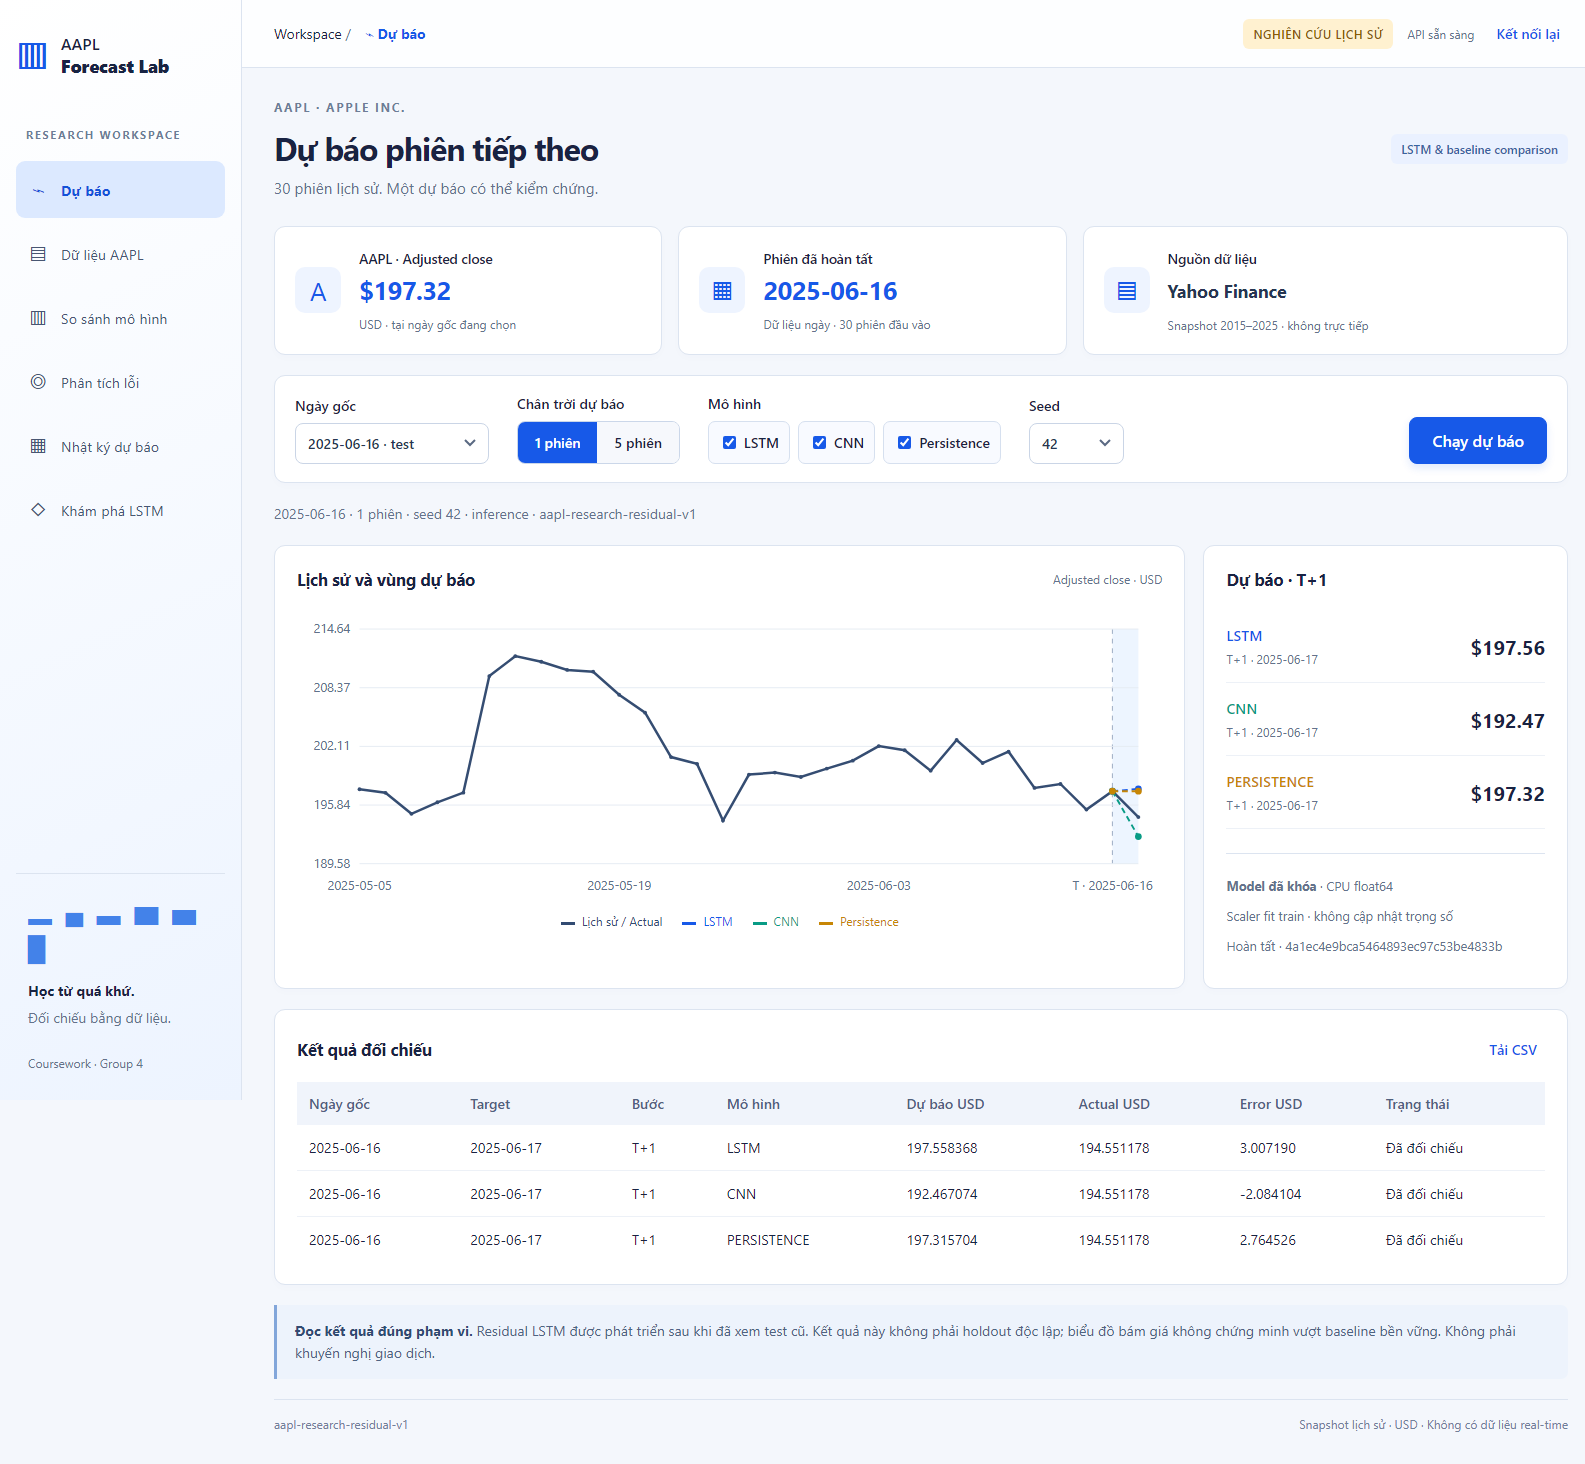

In [2]:
from IPython.display import Image
ui_pointer=json.loads((api_root/'logs/audit/tv6_item9_latest.json').read_text())
ui_receipt_path=api_root/ui_pointer['evidence']
ui_folder=ui_receipt_path.parent
ui_receipt=json.loads(ui_receipt_path.read_text())
assert ui_receipt['passed'] and ui_receipt['real_api'] and not ui_receipt['training']
for name,sha in ui_receipt['source_hashes'].items():
    assert hashlib.sha256((api_root/name).read_bytes()).hexdigest()==sha,name
ui_requests=json.loads((ui_folder/'prediction_requests.json').read_text())
assert [r['forecast_length'] for r in ui_requests]==[1,5]
assert all('target_values' not in r and 'input_values' not in r for r in ui_requests)
with TestClient(create_app(api_root)) as ui_api:
    replay=ui_api.post('/api/v1/predictions',json=ui_requests[1])
    assert replay.status_code==200,replay.text
    ui_replay=replay.json()
assert len(ui_replay['predictions'])==10 and ui_replay['status']=='complete'
display(pd.DataFrame(ui_replay['predictions'])[['forecast_origin','target_date','method','horizon_step','predicted_price']])
display(Image(filename=str(ui_folder/'forecast_h1_desktop.png'),width=1100))

### Nghiệm thu giao diện và giới hạn

        Kiểm browser thực: h1/h5, CNN disabled khi h5, xóa kết quả cũ, metric full/range, run/history, dữ liệu phân trang, stored errors, nhật ký, trace verified, responsive390px và lỗi mất backend. Test JavaScript kiểm request input-only, ghép comparison đúng key, escape dữ liệu và lỗi HTTP. Screenshot là kết quả API thật; chưa triển khai Internet, load test hoặc xác nhận máy khác. Mục10 còn audit cuối/tái lập/bàn giao.

,name,passed
0,"one step, three methods, actual comparison",True
1,"h5 disables and unchecks CNN, clears old result",True
2,"five steps, no CNN, actual API target dates",True
3,"full metrics display counts, scope and evaluat...",True
4,selected range is distinguished,True
5,error pagination scope and matched rows,True
6,data explorer shows real snapshot,True
7,data pagination works,True
8,journal retains actual completed requests,True
9,trace verified,True


,passed,browser,real_api,checks,unit_tests,release_sha256,training,independent_holdout,evidence
0,True,Chrome headless via CDP,True,14,5,a4b04a50c3e499b95407a5a8f9de379a40f6371bbb532c...,False,False,logs/audit/tv6_item9_20261127T091225920Z


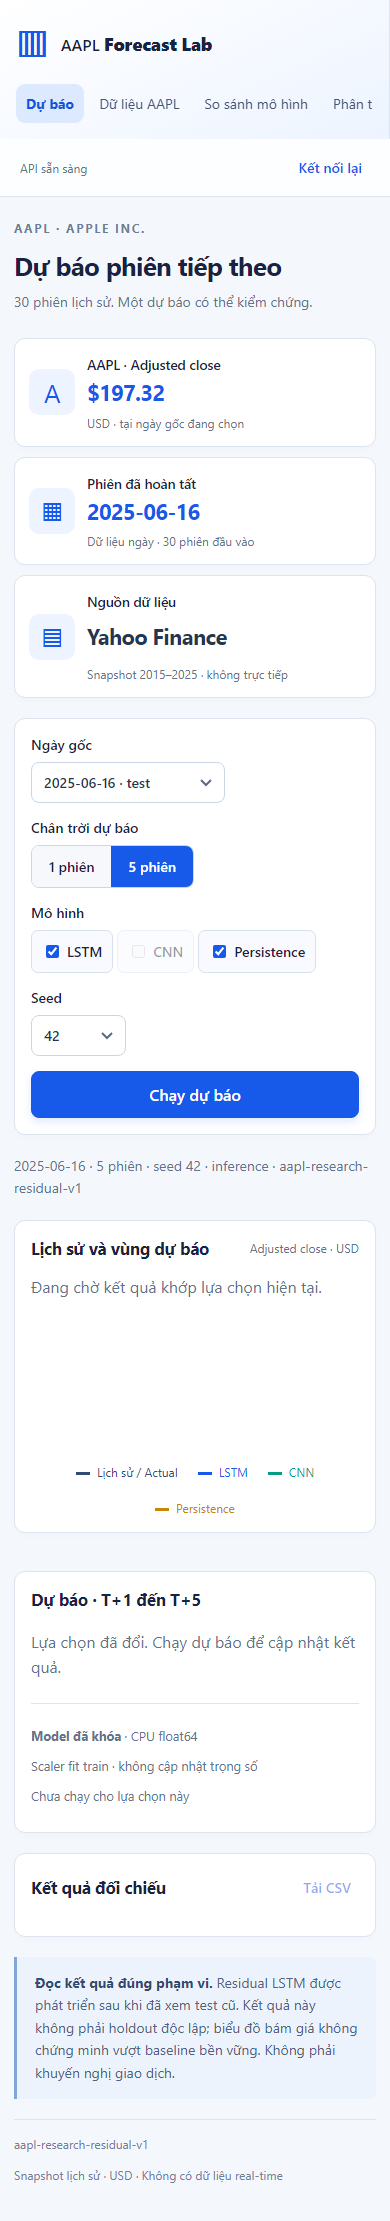

Bằng chứng: D:\learn_DeepLearning\Project_course-work\logs\audit\tv6_item9_20261127T091225920Z
Tiếp theo mục10: audit cuối, tái lập và bàn giao; chưa push hoặc upload.


In [3]:
ui_checks=json.loads((ui_folder/'checks.json').read_text())
assert len(ui_checks)==ui_receipt['checks'] and all(c['passed'] for c in ui_checks)
display(pd.DataFrame(ui_checks))
display(pd.DataFrame([{k:v for k,v in ui_receipt.items() if k!='source_hashes'}]))
display(Image(filename=str(ui_folder/'forecast_mobile.png'),width=300))
print('Bằng chứng:',ui_folder)
print('Tiếp theo mục10: audit cuối, tái lập và bàn giao; chưa push hoặc upload.')